# **Panorama Stitching from Scratch**
Feature detection (SIFT · ORB · Harris + MOPS) · matching · homography (DLT + RANSAC + Levenberg–Marquardt) · warping · multi-band blending

A panorama is a set of photographs of one scene, taken from one place with the camera turned between the shots, that has been *registered* (every image is mapped into a common frame) and *composited* (the overlaps are blended into one picture). The registration needs geometry, the composition needs the blending machinery of Part 1.

| stage | module (`src/panorama/`) | what is written from scratch |
| :--- | :--- | :--- |
| load, resize, grey | `stitcher.py` | OpenCV only reads the files and resizes |
| feature detection + description | `features.py`, `harris_mops.py` | **Harris + MOPS** completely; SIFT and ORB come from OpenCV (the assignment compares at least two extractors) |
| matching | `matching.py` | brute-force 2-NN, Lowe ratio test, one-to-one filter |
| homography | `homography.py` | normalised DLT, RANSAC, Levenberg–Marquardt, degeneracy tests |
| warping, canvas | `warp.py` | bilinear sampling, inverse warping, canvas layout |
| blending | `blend.py` | overwrite / average / feather / multi-band for K images, re-using Part 1's pyramid operators, gain compensation |
| evaluation | `synthetic.py`, `metrics.py`, `viz.py` | views with exact ground truth, error measures, figures |

The same pipeline is run with every extractor; only the first stage changes, so the comparison is fair.

![Panorama Stitching Pipeline](figures/pipeline_en.png)

**About the data.** The sample images of the course were not available when this part was written, so the notebook uses the stitching sets of the OpenCV test data (`data/panorama/input/<scene>/`, credit in `data/panorama/README.md`). To use other photos, put them in a new folder `data/panorama/input/<name>/` (any order, 2 or more images) and change `SCENE` below, or call `python run_panorama.py --folder <path>`.

In [ ]:
import io
import time
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
%matplotlib inline

from panorama import viz
from panorama.config import PANO_INPUT_DIR, PANO_RESULT_DIR, StitchConfig
from panorama.features import METHODS, DESCRIPTIONS, detect_and_describe
from panorama.homography import (
    apply_homography, dlt_conditioning, dlt_homography, normalize_points, ransac_homography, 
    refine_homography, reprojection_error, required_iterations
)
from panorama.matching import match_features
from panorama.metrics import homography_rms_error
from panorama.stitcher import PanoramaStitcher, list_images, load_images, preprocess
from panorama.synthetic import ViewSpec, render_views, SWEEPS, WORLD_WIDTH, sweep_pair
from panorama.warp import bilinear_sample, warp_perspective

viz.apply_style()


def show_fig(fig: plt.Figure, fmt: str = "png", dpi: int = 100, quality: int = 85) -> None:
    """
    Displays a matplotlib figure as an inline image.

    Saves the figure to an in-memory buffer as a PNG (ideal for charts) or a JPEG 
    (ideal for photographs, which helps keep the notebook size small), and displays it 
    using IPython.

    Args:
        fig (plt.Figure): The matplotlib figure object to display.
        fmt (str, optional): The image format to use ('png' or 'jpeg'). Defaults to "png".
        dpi (int, optional): The resolution in dots per inch. Defaults to 100.
        quality (int, optional): The image quality parameter, primarily for JPEG (1-100). 
            Defaults to 85.
    """
    buf = io.BytesIO()
    kw = {"pil_kwargs": {"quality": quality}} if fmt == "jpeg" else {}
    fig.savefig(buf, format=fmt, dpi=dpi, bbox_inches="tight", facecolor=viz.SURFACE, **kw)
    plt.close(fig)
    display(Image(data=buf.getvalue(), format=fmt))


def table(headers: list[str], rows: list[list], align: list[str] | None = None) -> None:
    """
    Renders and displays data as a formatted Markdown table.

    Args:
        headers (list[str]): A list of string headers for the table columns.
        rows (list[list]): A list of rows, where each row is a list of cell values.
        align (list[str] | None, optional): A list specifying the alignment for each 
            column (e.g., 'left', 'center', 'right'). Defaults to None.
    """
    display(Markdown(viz.markdown_table(headers, rows, align)))

## **Load the input images**

A scene is a folder of overlapping photographs. The images may be given in any order: the pipeline finds out by itself which images overlap.

boat [('boat1.jpg', 3888, 2592), ('boat2.jpg', 3888, 2592), ('boat3.jpg', 3888, 2592), ('boat4.jpg', 3888, 2592)] (name, width, height)


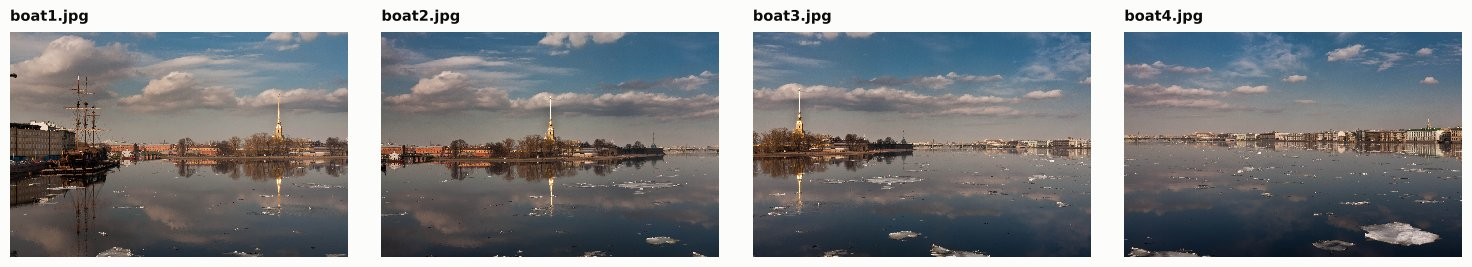

In [2]:
SCENE = "boat"

paths = list_images(PANO_INPUT_DIR / SCENE)
originals = load_images(paths)
print(SCENE, [(p.name, im.shape[1], im.shape[0]) for p, im in zip(paths, originals)], "(name, width, height)")

fig, axes = plt.subplots(1, len(originals), figsize=(15, 2.6))
for ax, p, im in zip(axes, paths, originals):
    viz.show_image(ax, im, p.name)
fig.tight_layout()
show_fig(fig, "jpeg")

## **Preprocessing**

* **Resize** so that the longer side is at most 1000 px (`cv2.INTER_AREA`, i.e. averaging over the area covered by each output pixel: shrinking with plain sub-sampling would alias). Every later cost (features, matching, warping, blending) scales with the number of pixels, and the RANSAC threshold of 3 px is expressed in pixels of these resized images.
* **Grey level**: the detectors work on one channel, $Y = 0.299R + 0.587G + 0.114B$. Colour is kept for the warping and the blending.

In [ ]:
imgs = preprocess(originals, max_side=1000)       # BGR uint8, longer side <= 1000
grays = [cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) for im in imgs]
print("after preprocessing:", [im.shape[:2] for im in imgs], "(height, width)")

after preprocessing: [(667, 1000), (667, 1000), (667, 1000), (667, 1000)] (height, width)


## **Geometry: why a homography?**

### ***The pinhole camera***

A 3-D point $\mathbf X = (X, Y, Z)^\top$ in the coordinate system of the camera ($x$ right, $y$ down, $Z$ along the optical axis) is imaged at the pixel

$$\tilde{\mathbf x} = \begin{bmatrix}u\\v\\1\end{bmatrix} \;\sim\; K\mathbf X, \qquad K = \begin{bmatrix} f & 0 & c_x\\ 0 & f & c_y\\ 0 & 0 & 1\end{bmatrix},$$

where $f$ is the focal length in pixels, $(c_x, c_y)$ the principal point and "$\sim$" means *equal up to a non-zero scale factor*. The scale that is lost is the depth $Z$: $\tilde{\mathbf x} = K\mathbf X / Z$, so every point of the ray $\lambda\mathbf X$ ($\lambda > 0$) lands on the same pixel.

### ***Two cameras with the same optical centre***

Put the common optical centre at the origin of the world coordinates and let camera $j$ have the orientation $R_j$ (camera → world). A world point $\mathbf X_w$ has the camera coordinates $\mathbf X_j = R_j^\top\mathbf X_w$, hence

$$\tilde{\mathbf x}_1 \sim K_1R_1^\top\mathbf X_w, \qquad \tilde{\mathbf x}_2 \sim K_2R_2^\top\mathbf X_w .$$

The first relation can be inverted up to the unknown depth, $\mathbf X_w = \lambda R_1K_1^{-1}\tilde{\mathbf x}_1$ for some $\lambda>0$. Insert it into the second one:

$$\tilde{\mathbf x}_2 \sim K_2R_2^\top\big(\lambda R_1K_1^{-1}\tilde{\mathbf x}_1\big) = \lambda\,K_2R_2^\top R_1K_1^{-1}\,\tilde{\mathbf x}_1 \quad\Longrightarrow\quad \boxed{\;\tilde{\mathbf x}_2 \sim H_{12}\,\tilde{\mathbf x}_1,\qquad H_{12} = K_2\,R_2^\top R_1\,K_1^{-1}\;}$$

because the factor $\lambda$ is absorbed by "$\sim$". The depth has **cancelled**: for a camera that only rotates, the mapping between two images is the same $3\times3$ matrix for *every* scene, flat or not. That is why a panorama can be stitched with a single global transformation per image.

*What if the camera also moves by $\mathbf t$?* Then $\tilde{\mathbf x}_2 \sim K_2R_2^\top(\lambda R_1K_1^{-1}\tilde{\mathbf x}_1 - \mathbf t)$ and $\lambda$ no longer cancels: the mapping depends on the depth of the point (**parallax**). It is still exact for a *planar* scene: for the plane $\mathbf n^\top\mathbf X_1 = d$ in the coordinates of camera 1 we have $\mathbf n^\top\mathbf X_1/d = 1$, so $\mathbf X_2 = R\mathbf X_1 + \mathbf t = (R + \mathbf t\mathbf n^\top/d)\mathbf X_1$ and $H = K_2(R + \mathbf t\mathbf n^\top/d)K_1^{-1}$. To first order the parallax of a translation $t$ shifts a point at depth $Z$ by $f\,t/Z$ pixels: with $f = 1944$ px, $t = 1$ cm and $Z = 1$ m that is 19 px, with $Z = 20$ m only 1 px. Hand-held panoramas of distant scenes work; close objects produce ghosts (see the limitations at the end).

### ***Properties that the pipeline uses***

1. $H$ is defined up to scale, so it has **8 degrees of freedom**. A correspondence $\mathbf x\leftrightarrow\mathbf x'$ gives two equations ($u$ and $v$), so **4 correspondences** determine $H$ and more are used to average out the noise.
2. Homographies are closed under products and inverses (they form the group $PGL(3)$): $H_{13} = H_{23}H_{12}$ and $H_{21} = H_{12}^{-1}$. Pairwise estimates can therefore be **chained** to bring all images into the frame of one reference image.
3. Lines are mapped to lines. Distances and angles are not. The third row $\mathbf h_3^\top$ of $H$ describes the perspective: the line $\mathbf h_3^\top\tilde{\mathbf x} = 0$ is sent to infinity.

### ***Numerical check with synthetic views***

`synthetic.py` renders views of one large photograph ("the world") through virtual cameras that only rotate, and returns the exact homographies $H_{ij} = K_jR_j^\top R_iK_i^{-1}$. We use these views here and for the controlled experiments at the end, because for them the ground truth is known. Test of the formula: warp view 0 into view 1 with $H_{01}$ and compare it with view 1; check the product rule.

overlap = 51% of view 1
mean |view 0 - view 1| without warping      :  30.2 grey levels
mean |H_01(view 0) - view 1| in the overlap :   0.7 grey levels  (two bilinear resamplings)
max |H_02 - H_12 H_01| = 2.842170943040401e-14


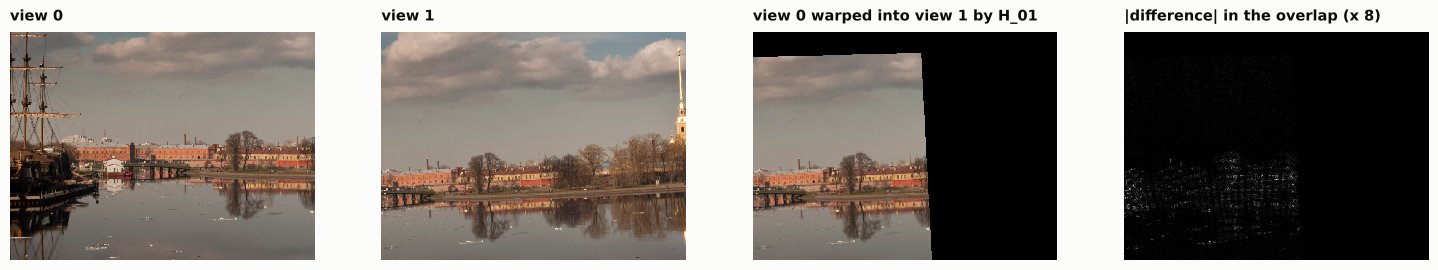

In [ ]:
world = cv2.imread(str(PANO_INPUT_DIR / "boat" / "boat1.jpg"))
world = cv2.resize(world, (WORLD_WIDTH, round(WORLD_WIDTH * world.shape[0] / world.shape[1])), interpolation=cv2.INTER_AREA)

specs = [ViewSpec(yaw=-5), ViewSpec(yaw=5, pitch=1.5, roll=3), ViewSpec(yaw=14, pitch=-1)]
views, H_gt, coverage = render_views(world, specs, size=(800, 600)) # H_gt[(i, j)] maps view i onto view j

v = [im.astype(np.float32) / 255 for im in views]
warped0, mask = warp_perspective(v[0], H_gt[(0, 1)], v[1].shape[:2])
inner = cv2.erode(mask.astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool)
gap_h = 255 * np.abs(warped0 - v[1]).mean(axis=2)
gap_0 = 255 * np.abs(v[0] - v[1]).mean(axis=2)
print(f"overlap = {inner.mean():.0%} of view 1")
print(f"mean |view 0 - view 1| without warping: {gap_0.mean():5.1f} grey levels")
print(f"mean |H_01(view 0) - view 1| in the overlap: {gap_h[inner].mean():5.1f} grey levels  (two bilinear resamplings)")

H02_chained = H_gt[(1, 2)] @ H_gt[(0, 1)]
H02_chained /= H02_chained[2, 2]
print("max |H_02 - H_12 H_01| =", np.abs(H_gt[(0, 2)] - H02_chained).max())

fig, axes = plt.subplots(1, 4, figsize=(15, 2.7))
viz.show_image(axes[0], views[0], "view 0")
viz.show_image(axes[1], views[1], "view 1")
viz.show_image(axes[2], np.clip(warped0 * 255, 0, 255).astype(np.uint8), "view 0 warped into view 1 by H_01")
viz.show_image(axes[3], np.clip(np.where(inner, gap_h, 0) * 8, 0, 255).astype(np.uint8), "|difference| in the overlap (x 8)")
fig.tight_layout()
show_fig(fig, "jpeg")

## **Feature detection and description**

### ***What do we ask from a feature?***

The correspondences are the only input of the geometry, so their quality decides everything after them.

* **Repeatable**: the same scene point is detected in both images in spite of the change of view, of rotation, scale, exposure and noise.
* **Distinctive**: the descriptor of a point is far from the descriptors of all other points, otherwise matching is ambiguous.
* **Well localised**: an error of $\varepsilon$ px in a keypoint becomes an error of the same size in $H$.
* **Plentiful and spread out** over the overlap: the estimate of $H$ is poorly conditioned if all matches sit in a small region (shown in the homography section).

Between two photographs of a panorama the image content is moved and rotated (roll of the camera), can be zoomed (different focal length or distance) and changes brightness (auto exposure). A detector/descriptor pair should therefore be invariant to **translation, rotation, scale and gain/bias** of the intensity.

### ***Harris corners from first principles*** (written from scratch)

How well can a small window around $(x,y)$ be localised? Shift it by $\Delta = (\Delta x, \Delta y)$ and measure the change, weighted by a window function $w$:

$$E(\Delta) = \sum_{(x,y)} w(x,y)\,\big[I(x+\Delta x, y+\Delta y) - I(x,y)\big]^2 .$$

For small shifts the first-order Taylor expansion $I(x+\Delta) \approx I(x) + \nabla I^\top\Delta$ gives

$$E(\Delta) \approx \Delta^\top M\,\Delta, \qquad M = \sum w\begin{bmatrix} I_x^2 & I_xI_y\\ I_xI_y & I_y^2\end{bmatrix}\quad\text{(structure tensor).}$$

$M$ is symmetric positive semi-definite. Its eigenvectors are the directions of the largest and smallest change of the image, its eigenvalues $\lambda_1\ge\lambda_2\ge0$ are the corresponding curvatures of $E$ (the level sets of $E$ are ellipses with semi-axes $\propto\lambda^{-1/2}$). Three cases:

* **flat** region: $\lambda_1\approx\lambda_2\approx0$, any shift is invisible;
* **edge**: $\lambda_1\gg\lambda_2\approx0$, a shift *along* the edge is invisible (the aperture problem), the position is only known across the edge;
* **corner**: $\lambda_2$ is large too, every shift changes the window, the position is unique.

A corner is therefore a point where the **smaller** eigenvalue is large. Computing eigenvalues per pixel is avoidable: $\det M = \lambda_1\lambda_2$ and $\operatorname{tr}M = \lambda_1+\lambda_2$. Harris and Stephens use $\det M - k\operatorname{tr}^2M$ with a tuning constant $k$. The multi-scale oriented patches (MOPS) of Brown, Szeliski and Winder use the **harmonic mean** of the eigenvalues,

$$f_{HM} = \frac{\det M}{\operatorname{tr}M} = \frac{\lambda_1\lambda_2}{\lambda_1+\lambda_2} = \frac{1}{1/\lambda_1 + 1/\lambda_2}, \qquad \tfrac12\lambda_2 \;\le\; f_{HM} \;\le\; \lambda_2 ,$$

(the bounds follow from $1/\lambda_1 \le 1/\lambda_2$ and $1/\lambda_1 + 1/\lambda_2 \ge 1/\lambda_2$): it is within a factor of 2 of the smaller eigenvalue, without eigen-decomposition and without a constant $k$. In the code the gradients are computed after a Gaussian smoothing with $\sigma_d = 1$ and $M$ is accumulated with a Gaussian window $\sigma_i = 1.5$ (smooth weights keep the response rotation invariant; a box window would not).

$M$ is rotated by $R^\top M R$ when the image is rotated, so its eigenvalues do not change: **the detector is rotation invariant**. It is *not* scale invariant: a corner seen from far away is an edge-like curve when zoomed in. Scale is handled with a Gaussian pyramid (4 levels, factor 2). The corner strength is computed on every level, local maxima are refined to sub-pixel accuracy by a parabola through the three samples around the maximum (per axis), and then **adaptive non-maximal suppression** (ANMS) selects the keypoints: the point $i$ gets the suppression radius $r_i = \min_j\{\|x_i-x_j\| : c\,f_j > f_i\}$ ($c = 0.9$), the distance to the nearest point that is clearly stronger, and the $N$ points with the largest radii are kept. The strongest points of an image cluster on a few highly textured spots; ANMS spreads the keypoints evenly, which is what the homography needs.

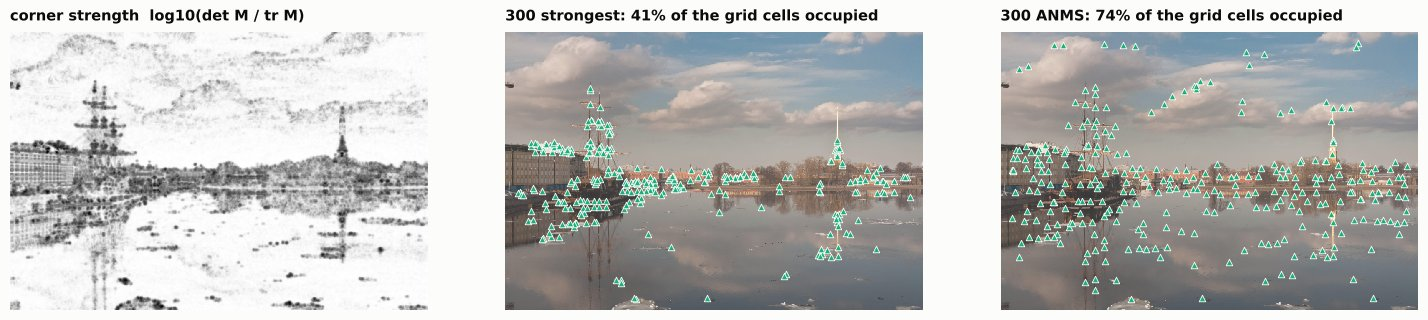

1646 candidate corners on the finest level


In [5]:
from panorama.harris_mops import harris_response, _peaks, anms, detect_harris_mops, _describe_level

img0 = grays[0].astype(np.float32) / 255
R = harris_response(img0)                                         # f_HM = det(M) / tr(M) at every pixel
xs, ys, fs = _peaks(R, thresh_rel=0.01, max_candidates=3000)       # 3x3 local maxima above 1 % of the strongest, sub-pixel
N = 300
strongest = np.argsort(-fs)[:N]                                    # plain "N strongest corners"
spread = anms(np.stack([xs, ys], axis=1), fs, N)                   # adaptive non-maximal suppression


def occupancy(x, y, shape, cells=(12, 8)):
    """Fraction of the cells of a regular grid that contain at least one keypoint."""
    gx = np.minimum((x / shape[1] * cells[0]).astype(int), cells[0] - 1)
    gy = np.minimum((y / shape[0] * cells[1]).astype(int), cells[1] - 1)
    return len(set(zip(gx, gy))) / (cells[0] * cells[1])


wash = (imgs[0].astype(np.float32) * 0.78 + 255 * 0.22).astype(np.uint8)
col = viz.SERIES["harris"]["color"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
axes[0].imshow(np.log10(R + 1e-6), cmap="Greys")
axes[0].set_axis_off(); axes[0].grid(False)
axes[0].set_title("corner strength  log10(det M / tr M)", loc="left")
for ax, sel, name in ((axes[1], strongest, "strongest"), (axes[2], spread, "ANMS")):
    viz.show_image(ax, wash)
    ax.scatter(xs[sel], ys[sel], s=22, color=col, marker="^", edgecolors=viz.SURFACE, linewidths=0.6)
    ax.set_title(f"{N} {name}: {occupancy(xs[sel], ys[sel], img0.shape):.0%} of the grid cells occupied", loc="left")
fig.tight_layout()
show_fig(fig, "jpeg")
print(f"{len(xs)} candidate corners on the finest level")

### ***The MOPS descriptor*** (written from scratch)

* **Orientation.** The gradient of a *heavily* blurred image ($\sigma_o = 4.5$) is stable under noise and small localisation errors; its direction $\theta=\operatorname{atan2}(\partial_y\tilde I,\partial_x\tilde I)$ at the keypoint is the dominant orientation. Rotating the sampling grid by $\theta$ makes the descriptor rotation invariant.
* **Sampling.** An $8\times8$ grid with spacing 5 px (a 40 × 40 px oriented window) is sampled bilinearly from the pyramid level after a Gaussian blur with $\sigma = 2$. The blur is the anti-aliasing filter of the sub-sampling: taking every fifth pixel of the sharp image would alias.
* **Bias/gain normalisation.** Each patch $d$ is replaced by $\hat d = (d - \bar d)/s_d$ ($s_d$ = standard deviation of the 64 samples). Under a change of exposure $I\mapsto aI+b$ with $a>0$ we have $\overline{aI+b} = a\bar I + b$ and $s_{aI+b} = a\,s_I$, so $\hat d$ is **unchanged** (up to float rounding and the $10^{-6}$ that keeps the division finite on a flat patch).
* **Distance.** For normalised patches ($\sum_k\hat d_k = 0$, $\sum_k\hat d_k^2 = n = 64$) the Euclidean distance is a correlation: $\|\hat d_a-\hat d_b\|^2 = 2n(1-\rho_{ab})$, where $\rho_{ab}$ is the normalised cross-correlation of the two patches. Matching with $L_2$ is matching by NCC.

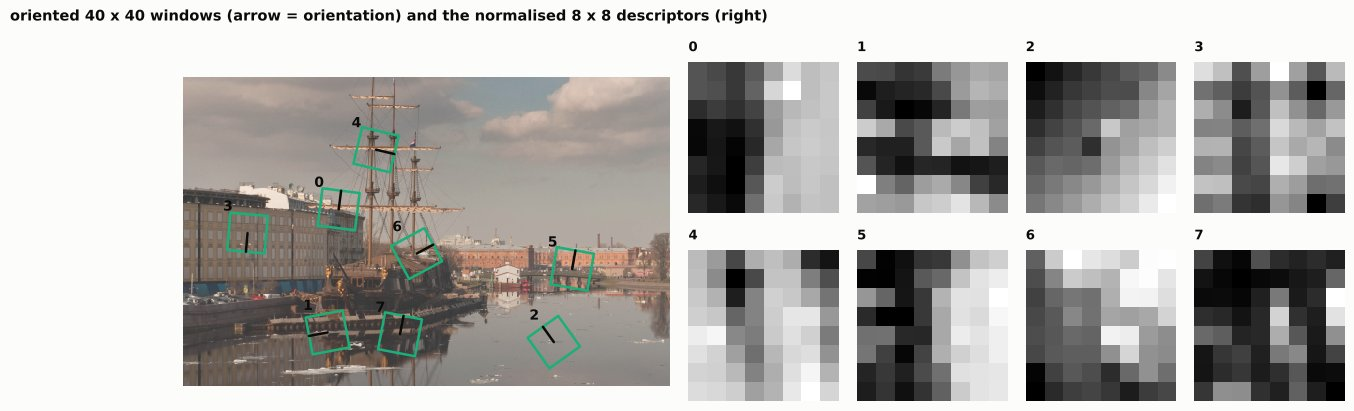

In [6]:
pts, desc, size, resp = detect_harris_mops(grays[0])                  # what detect_and_describe(gray, "harris") does
fine = np.flatnonzero(size == 40)                                     # keypoints of the finest pyramid level (window 40 px)
x0, x1, y0, y1 = 0, 520, 150, 480                                     # a crop with plenty of structure
inside = fine[(pts[fine, 0] > x0 + 30) & (pts[fine, 0] < x1 - 30) & (pts[fine, 1] > y0 + 30) & (pts[fine, 1] < y1 - 30)]
pick = []
for k in np.random.default_rng(5).permutation(inside):                # 8 keypoints that are not on top of each other
    if all(np.hypot(*(pts[k] - pts[j])) > 70 for j in pick):
        pick.append(k)
    if len(pick) == 8:
        break

oy, ox = np.gradient(cv2.GaussianBlur(img0, (0, 0), 4.5))             # gradient of the heavily blurred image
fig = plt.figure(figsize=(15, 4.4))
gs = fig.add_gridspec(2, 7, wspace=0.12, hspace=0.25)
ax = fig.add_subplot(gs[:, :3])
viz.show_image(ax, wash[y0:y1, x0:x1])
for c, k in enumerate(pick):
    x, y = pts[k][0] - x0, pts[k][1] - y0
    theta = np.arctan2(bilinear_sample(oy, pts[k][0], pts[k][1])[0], bilinear_sample(ox, pts[k][0], pts[k][1])[0])
    Rot = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
    box = (Rot @ np.array([[-20, -20], [20, -20], [20, 20], [-20, 20], [-20, -20]]).T).T + [x, y]
    ax.plot(box[:, 0], box[:, 1], color=col, linewidth=1.8)
    ax.plot([x, x + 20 * np.cos(theta)], [y, y + 20 * np.sin(theta)], color=viz.INK, linewidth=1.8)
    ax.text(x - 26, y - 24, str(c), color=viz.INK, fontsize=10, fontweight="bold")
    axp = fig.add_subplot(gs[c // 4, 3 + c % 4])
    axp.imshow(desc[k].reshape(8, 8), cmap="gray", interpolation="nearest")
    axp.set_axis_off(); axp.grid(False)
    axp.set_title(str(c), fontsize=9.5, loc="left")
fig.suptitle("oriented 40 x 40 windows (arrow = orientation) and the normalised 8 x 8 descriptors (right)", x=0.01, ha="left", y=1.0, fontsize=10.5, fontweight="bold")
show_fig(fig, "jpeg")

In [7]:
# Invariance of the descriptor to I -> a I + b, and descriptor distance = correlation
xy = np.stack([xs[spread], ys[spread]], axis=1)[:200]                  # 200 keypoints (coordinates of the finest level)
d1 = _describe_level(img0, xy)
d2 = _describe_level(0.4 * img0 + 0.2, xy)                             # gain 0.4, bias 0.2
print(f"|d(I) - d(0.4 I + 0.2)|           : median {np.median(np.abs(d1 - d2)):.1e}, max {np.abs(d1 - d2).max():.1e}   (the entries of d are of order 1)")

d3 = d1[np.random.default_rng(0).permutation(len(d1))]                 # descriptors of other keypoints
rho = (d1 * d3).mean(axis=1)                                           # NCC of two zero-mean, unit-variance patches
dist2 = ((d1 - d3) ** 2).sum(axis=1)
print(f"| ||d_a - d_b||^2 - 2n(1 - rho) |   : max {np.abs(dist2 - 2 * 64 * (1 - rho)).max():.1e}   (n = 64; the squared distances are {dist2.mean():.0f} on average)")

|d(I) - d(0.4 I + 0.2)|           : median 1.8e-05, max 2.3e-03   (the entries of d are of order 1)
| ||d_a - d_b||^2 - 2n(1 - rho) |   : max 2.2e-02   (n = 64; the squared distances are 100 on average)


### ***SIFT*** (OpenCV)

* **Scale-space.** $L(x,y,\sigma) = G_\sigma * I$. The *scale-normalised* Laplacian $\sigma^2\nabla^2 L$ is independent of the zoom: if image 2 is image 1 magnified by $a$, then $L_2(ax, a\sigma) = L_1(x,\sigma)$, hence $\nabla^2L_2 = a^{-2}\nabla^2L_1$ and $(a\sigma)^2\nabla^2L_2 = \sigma^2\nabla^2L_1$. Extrema over $(x, y, \sigma)$ of this quantity are blobs that are found at corresponding positions *and* scales in both images ($\sigma$ is proportional to the blob size).
* **Difference of Gaussians.** The Gaussian solves the heat equation, $\partial G/\partial\sigma = \sigma\nabla^2G$, so $G_{k\sigma} - G_\sigma \approx (k-1)\sigma\,\partial G/\partial\sigma = (k-1)\,\sigma^2\nabla^2G$: a DoG is the scale-normalised Laplacian times the constant $(k-1)$, which is the same on all levels because the scales form a geometric sequence. Subtracting two blurred images is much cheaper than a Laplacian at every scale.
* **Keypoints** are the 26-neighbourhood extrema of the DoG stack, refined by a quadratic fit in $(x,y,\sigma)$; low-contrast points (threshold on $|D|$, `contrastThreshold` = 0.04, an **absolute** value) and edge points (ratio of the principal curvatures $\operatorname{tr}^2/\det$ above a limit) are rejected.
* **Orientation**: peak of a 36-bin histogram of gradient directions in a window of size $\propto\sigma$. **Descriptor**: gradients in the window rotated by that angle and scaled by $\sigma$, accumulated in $4\times4$ spatial cells × 8 orientation bins = **128 numbers**, normalised to unit length, clipped at 0.2 and normalised again. The normalisation removes the gain; the clipping reduces the influence of a few very strong gradients (saturation, non-linear illumination changes).

### ***ORB*** (OpenCV)

* **oFAST.** A pixel $p$ is a FAST corner if a contiguous arc of at least 9 of the 16 pixels of the circle of radius 3 around it are all brighter than $I_p + t$ or all darker than $I_p - t$, with `fastThreshold` $t = 20$ grey levels (an **absolute** threshold). Corners are ranked by the Harris measure, the best $N$ are kept; detection runs on an 8-level pyramid with factor 1.2. The orientation is the direction from the corner to the **intensity centroid** of a circular patch, $\theta=\operatorname{atan2}(m_{01}, m_{10})$ with the moments $m_{pq}=\sum x^py^qI(x,y)$.
* **rBRIEF.** 256 binary intensity comparisons $[\,I(\mathbf p+\mathbf a_i) < I(\mathbf p+\mathbf b_i)\,]$ on the smoothed patch, with the pair pattern rotated by $\theta$ (steered BRIEF; the angle is quantised in steps of 12°). The pairs were chosen offline for high variance and low correlation. The descriptor is **32 bytes** compared with the **Hamming distance** (XOR + popcount), which is extremely cheap. The test $I_a < I_b$ is invariant to any monotonic change of intensity — but the *detector* threshold is not (see the experiments).

### ***Summary of the three extractors***

| | SIFT (OpenCV) | ORB (OpenCV) | Harris + MOPS (from scratch) |
| :--- | :--- | :--- | :--- |
| detector | DoG extrema (blobs) | oFAST corners | harmonic-mean Harris corners + ANMS |
| scales | continuous, ≈ 3 per octave | 8 levels, factor 1.2 | 4 octaves (factor 2) |
| orientation | dominant gradient direction | intensity centroid | direction of the blurred gradient |
| descriptor | 128 floats, histograms of gradients | 256 bits, intensity comparisons | 64 floats, normalised patch |
| distance | $L_2$ | Hamming | $L_2$ |
| gain / bias | gain: normalisation; contrast threshold absolute | comparisons invariant; FAST threshold absolute | exact (normalised patch); relative thresholds |

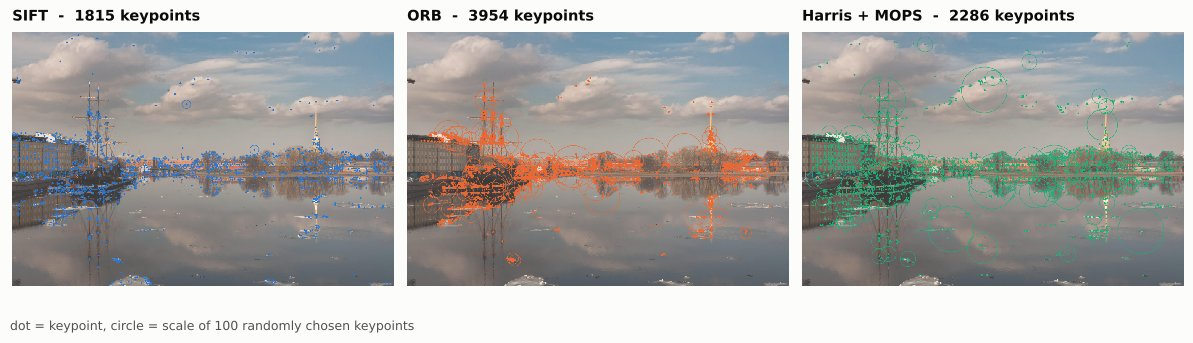

| extractor | keypoints | descriptor (bytes) | distance | time (ms) |
| :--- | ---: | ---: | :--- | ---: |
| SIFT (OpenCV) | 1815 | 512 | L2 | 100 |
| ORB (OpenCV) | 3954 | 32 | Hamming | 15 |
| Harris + MOPS (from scratch) | 2286 | 256 | L2 | 52 |

In [8]:
feats0 = {m: detect_and_describe(grays[0], m, max_keypoints=4000) for m in METHODS}
show_fig(viz.keypoint_figure(imgs[0], feats0), "jpeg")
table(["extractor", "keypoints", "descriptor (bytes)", "distance", "time (ms)"],
      [[DESCRIPTIONS[m], len(f), f.desc.shape[1] * f.desc.itemsize, "Hamming" if f.binary else "L2", f"{1000 * f.seconds:.0f}"]
       for m, f in feats0.items()], "lrrlr")

### ***A pitfall: where is the centre of a pixel?***

The homography maps *coordinates*, so every part of the pipeline must use the same convention. Here (as in `cv2.warpPerspective`) the centre of the top-left pixel is $(0,0)$. OpenCV's SIFT and ORB do **not** follow this exactly:

* SIFT's first octave is the $2\times$ up-sampled image. Index $u$ of the up-sampled image lies at $u/2 - 1/4$ in the input (pixel-centre mapping $x = (u+\tfrac12)/2 - \tfrac12$) but OpenCV reports $u/2$. All later octaves are decimated from that image, so *every* SIFT keypoint is shifted by $+\tfrac14$ px.
* ORB works on pyramid levels with rounded sizes $(\operatorname{round}(W/s_l), \operatorname{round}(H/s_l))$ and reports $x_l s_l$ instead of $(x_l+\tfrac12)W/W_l - \tfrac12$: a bias that depends on the level.

The bias is invisible while two views are processed identically (it cancels). It does **not** cancel when the views are rotated or scaled against each other. An exact $180^\circ$ rotation exposes it: the keypoint at $(x,y)$ must reappear at $(W-1-x, H-1-y)$. If every keypoint is reported with a bias $\mathbf b$, the residual is $2\mathbf b$. `features.py` removes the bias (`fix_coords=True`); the test below shows the residual before and after.

In [9]:
h, w = grays[0].shape
flipped = grays[0][::-1, ::-1].copy()              # exact 180-degree rotation: pixel (x, y) -> (w-1-x, h-1-y)
rows = []
for m in METHODS:
    for fix in ((False, True) if m != "harris" else (True,)):
        f1 = detect_and_describe(grays[0], m, 4000, fix_coords=fix)
        f2 = detect_and_describe(flipped, m, 4000, fix_coords=fix)
        mt = match_features(f1, f2, ratio=0.8)
        p1, p2 = f1.kpts[mt.idx1].astype(float), f2.kpts[mt.idx2].astype(float)
        res = p2 - np.stack([w - 1 - p1[:, 0], h - 1 - p1[:, 1]], axis=1)       # 0 if the coordinates are exact
        r = res[np.linalg.norm(res, axis=1) < 6]                                  # discard the few wrong matches
        rows.append([DESCRIPTIONS[m], "pixel-centre correction" if fix and m != "harris" else ("none (own code)" if m == "harris" else "none (raw OpenCV)"),
                     len(r), f"{r[:, 0].mean():+.3f}", f"{r[:, 1].mean():+.3f}", f"{np.sqrt((r ** 2).sum(1).mean()):.3f}"])
table(["extractor", "coordinates", "matches", "mean dx (px)", "mean dy (px)", "rms (px)"], rows, "llrrrr")

| extractor | coordinates | matches | mean dx (px) | mean dy (px) | rms (px) |
| :--- | :--- | ---: | ---: | ---: | ---: |
| SIFT (OpenCV) | none (raw OpenCV) | 1631 | +0.505 | +0.496 | 0.751 |
| SIFT (OpenCV) | pixel-centre correction | 1631 | +0.005 | -0.004 | 0.251 |
| ORB (OpenCV) | none (raw OpenCV) | 3954 | -0.842 | -0.767 | 1.687 |
| ORB (OpenCV) | pixel-centre correction | 3954 | +0.000 | +0.000 | 0.000 |
| Harris + MOPS (from scratch) | none (own code) | 2260 | +0.000 | +0.005 | 0.313 |

## **Matching**

### ***Nearest neighbours with one matrix product***

For the descriptors $\mathbf a_i$ of image 1 and $\mathbf b_j$ of image 2,

$$\|\mathbf a_i - \mathbf b_j\|^2 = \|\mathbf a_i\|^2 + \|\mathbf b_j\|^2 - 2\,\mathbf a_i^\top\mathbf b_j ,$$

so the whole $N_1\times N_2$ matrix of squared distances is two vectors of squared norms plus $-2AB^\top$: a single matrix product (BLAS) instead of $N_1N_2$ distance evaluations in Python. Rounding can make a tiny distance slightly negative, therefore it is clamped at 0 before the square root. Rows are processed in chunks of 1024 to bound the memory, and `argpartition` finds the two smallest entries of a row in $O(N_2)$ without sorting.

**Hamming distance with the same trick.** For bit vectors $\mathbf a,\mathbf b\in\{0,1\}^n$ we have $|a_k-b_k| = (a_k-b_k)^2$ because the values are 0 or 1, hence $d_H(\mathbf a,\mathbf b) = \sum_k|a_k-b_k| = \|\mathbf a-\mathbf b\|^2$: the ORB bytes are unpacked to 256 bits and the same code applies.

In [10]:
from panorama.matching import knn2

rng = np.random.default_rng(0)
a = rng.normal(size=(60, 16)).astype(np.float32)
b = rng.normal(size=(90, 16)).astype(np.float32)
idx, dist = knn2(a, b, binary=False)
D = np.linalg.norm(a[:, None] - b[None], axis=2)                                     # brute force
print("L2     : max |distance - brute force| =", float(np.abs(dist - np.sort(D, axis=1)[:, :2]).max()),
      "| returned neighbour is a nearest one:", bool((D[np.arange(60), idx[:, 0]] == D.min(axis=1)).all()))

ba = rng.integers(0, 256, size=(60, 32), dtype=np.uint8)
bb = rng.integers(0, 256, size=(90, 32), dtype=np.uint8)
idx, dist = knn2(ba, bb, binary=True)
Hd = np.unpackbits(ba[:, None, :] ^ bb[None, :, :], axis=2).sum(axis=2)              # popcount of the XOR
print("Hamming: max |distance - brute force| =", float(np.abs(dist - np.sort(Hd, axis=1)[:, :2]).max()),
      "| returned neighbour is a nearest one:", bool((Hd[np.arange(60), idx[:, 0]] == Hd.min(axis=1)).all()))

L2     : max |distance - brute force| = 9.5367431640625e-07 | returned neighbour is a nearest one: True
Hamming: max |distance - brute force| = 0.0 | returned neighbour is a nearest one: True


### ***The ratio test and the one-to-one filter***

The nearest neighbour is wrong whenever the point has no counterpart (it lies outside the overlap, is occluded, or the structure repeats). The distance $d_1$ to the nearest neighbour alone cannot tell, because the descriptors of different images are not comparable in absolute terms. **Lowe's ratio test** accepts a match only if $d_1/d_2 < \tau$ ($d_2$ = distance to the second-nearest neighbour). For a point that has no counterpart, $d_1$ and $d_2$ are two samples of the same distribution (the distance to some unrelated descriptor), so the ratio is close to 1; for a correct match $d_1$ is small and $d_2$ is typical, the ratio is small. $\tau$ trades the number of correct matches against their purity.

The **one-to-one filter** adds a physical constraint: in a static scene a point of image 2 is the image of at most one point of image 1. When several features of image 1 pick the same partner, only the most distinctive one (smallest ratio) is kept. Without it, repeated texture (lines of text, windows, tiles) can produce many matches that collapse on a single point (an example is shown in the homography section).

With the synthetic pair of known geometry we can measure what the test does: a nearest-neighbour match is *correct* if the true homography maps the keypoint of image 1 to within 3 px of the matched keypoint of image 2.

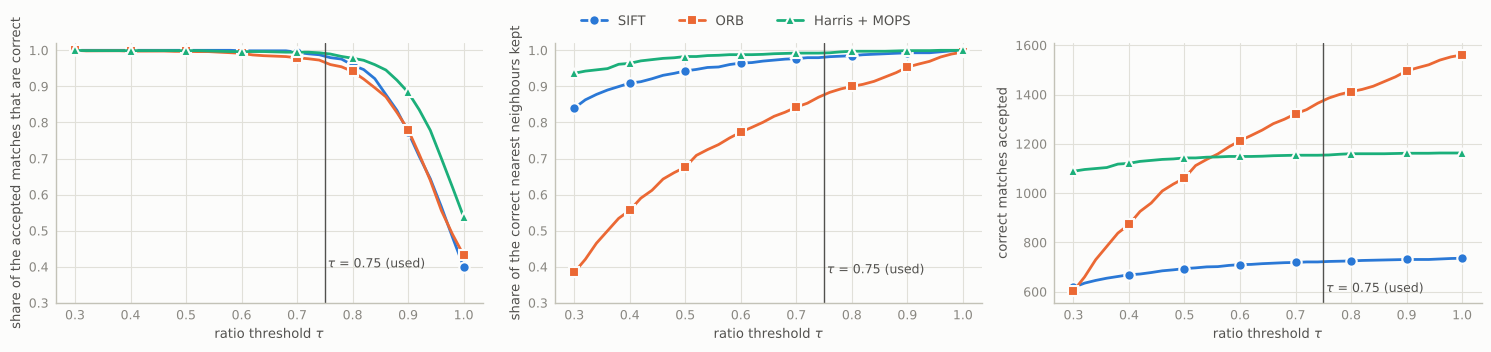

| extractor | keypoints (image 1) | accepted at 0.75 | of which correct | precision | recall |
| :--- | ---: | ---: | ---: | ---: | ---: |
| SIFT (OpenCV) | 1838 | 730 | 721 | 98.8 % | 98.0 % |
| ORB (OpenCV) | 3915 | 1403 | 1365 | 97.3 % | 87.0 % |
| Harris + MOPS (from scratch) | 2160 | 1162 | 1154 | 99.3 % | 99.2 % |

In [11]:
pair_views, H_pair, _ = render_views(world, [ViewSpec(yaw=-4), ViewSpec(yaw=4)], size=(800, 600))      # 8 degrees apart
pg = [cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) for im in pair_views]
taus = np.linspace(0.3, 1.0, 36)
curves, rows = {}, []
for m in METHODS:
    f1, f2 = (detect_and_describe(g, m, 4000) for g in pg)
    idx, dist = knn2(f1.desc, f2.desc, f1.binary)
    ratio = dist[:, 0] / dist[:, 1]
    correct = reprojection_error(H_pair[(0, 1)], f1.kpts, f2.kpts[idx[:, 0]]) < 3.0       # agrees with the true geometry
    keep = ratio[None, :] < taus[:, None]                                                  # (thresholds, queries)
    n_ok = (keep & correct[None, :]).sum(axis=1)
    curves[m] = dict(precision=n_ok / np.maximum(keep.sum(axis=1), 1), recall=n_ok / correct.sum(), n_ok=n_ok)
    k = int(np.argmin(np.abs(taus - 0.75)))
    rows.append([DESCRIPTIONS[m], len(f1), int(keep[k].sum()), int(n_ok[k]), f"{100 * curves[m]['precision'][k]:.1f} %", f"{100 * curves[m]['recall'][k]:.1f} %"])

fig, axes = plt.subplots(1, 3, figsize=(15, 3.3))
for ax, key, label in zip(axes, ("precision", "recall", "n_ok"),
                          ("share of the accepted matches that are correct", "share of the correct nearest neighbours kept", "correct matches accepted")):
    for m in METHODS:
        s = viz.SERIES[m]
        ax.plot(taus, curves[m][key], color=s["color"], marker=s["marker"], markevery=5, markeredgecolor=viz.SURFACE, markeredgewidth=1.5)
    ax.axvline(0.75, color=viz.INK2, linewidth=1.0)
    ax.set_xlabel("ratio threshold $\\tau$")
    ax.set_ylabel(label)
    ax.text(0.755, ax.get_ylim()[0] + 0.04 * np.diff(ax.get_ylim())[0], "$\\tau$ = 0.75 (used)", color=viz.INK2, fontsize=9)
axes[0].set_ylim(0.3, 1.02); axes[1].set_ylim(0.3, 1.02)
fig.legend(handles=viz.method_handles(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.07), columnspacing=2.5)
fig.tight_layout()
show_fig(fig)
table(["extractor", "keypoints (image 1)", "accepted at 0.75", "of which correct", "precision", "recall"], rows, "lrrrrr")

## **Homography estimation**

### ***Direct Linear Transform (DLT)***

A correspondence $\mathbf x = (x, y, 1)^\top\leftrightarrow\mathbf x' = (u, v, 1)^\top$ satisfies $\mathbf x'\sim H\mathbf x$. In homogeneous coordinates "equal up to scale" means *parallel*, i.e. the cross product vanishes: $\mathbf x'\times H\mathbf x = \mathbf 0$. With the rows $\mathbf h_k^\top$ of $H$, $H\mathbf x = (\mathbf h_1^\top\mathbf x,\ \mathbf h_2^\top\mathbf x,\ \mathbf h_3^\top\mathbf x)^\top$ and

$$\mathbf x'\times H\mathbf x = \begin{bmatrix} v\,\mathbf h_3^\top\mathbf x - \mathbf h_2^\top\mathbf x\\ \mathbf h_1^\top\mathbf x - u\,\mathbf h_3^\top\mathbf x\\ u\,\mathbf h_2^\top\mathbf x - v\,\mathbf h_1^\top\mathbf x\end{bmatrix} = \mathbf 0 .$$

The three equations are linearly dependent: $u\cdot(\text{row 1}) + v\cdot(\text{row 2}) + (\text{row 3}) = 0$ (all terms cancel). Only two are independent, which is the "2 equations per correspondence" of the degrees-of-freedom count. Written for $\mathbf h = (\mathbf h_1;\mathbf h_2;\mathbf h_3)\in\mathbb R^9$:

$$\begin{bmatrix}0&0&0&-x&-y&-1&vx&vy&v\\ x&y&1&0&0&0&-ux&-uy&-u\end{bmatrix}\mathbf h = \mathbf 0 .$$

Stacking $N\ge4$ correspondences gives $A\mathbf h=\mathbf 0$ with $A\in\mathbb R^{2N\times9}$. For $N=4$ the matrix has rank 8 and its null space is the exact solution. With noise and $N>4$ there is no exact solution, and we minimise the algebraic error:

$$\min_{\|\mathbf h\|=1}\|A\mathbf h\|^2 .$$

**The minimiser is the right singular vector of the smallest singular value.** Let $A = U\Sigma V^\top$ and $\mathbf c = V^\top\mathbf h$. Then $\|A\mathbf h\|^2 = \|\Sigma\mathbf c\|^2 = \sum_k\sigma_k^2c_k^2$ with $\sum_kc_k^2 = \|\mathbf h\|^2 = 1$: a weighted average of the $\sigma_k^2$, which is smallest, $\sigma_{\min}^2$, when all the weight sits on the smallest singular value, $\mathbf c = \mathbf e_9$, i.e. $\mathbf h = \mathbf v_9$, the last column of $V$ (`Vt[-1]` in the code). $\blacksquare$

### ***Hartley normalisation***

The entries of $A$ have very different sizes ($1$, $x\sim10^3$, $ux\sim10^6$), so $A$ is badly conditioned and the equations with large coordinates dominate the sum. Worse, the algebraic error depends on the *coordinate frame*: moving the origin or changing the unit of the pixel coordinates changes the minimiser. The cure is to normalise both point sets by a similarity,

$$\hat{\mathbf x} = T\mathbf x,\quad \hat{\mathbf x}' = T'\mathbf x',\qquad T:\ \text{centroid}\to\text{origin},\ \text{mean distance to the origin}\to\sqrt2,$$

to solve for $\hat H$ with $\hat{\mathbf x}'\sim\hat H\hat{\mathbf x}$ and to undo it, $H = T'^{-1}\hat HT$ (because $T'\mathbf x'\sim\hat HT\mathbf x\iff\mathbf x'\sim T'^{-1}\hat HT\mathbf x$). $T$ and $T'$ are defined by the data and transform covariantly under a change of origin and unit, so the estimate no longer depends on the frame. The experiments below show the three effects: conditioning, frame independence, and — the case that matters for stitching — matches concentrated in a small region.

In [12]:
from panorama.synthetic import rotation_matrix

rng = np.random.default_rng(1)
K = np.array([[1944, 0, 399.5], [0, 1944, 299.5], [0, 0, 1]])
H_true = K @ rotation_matrix(8, 1.5, 2).T @ np.linalg.inv(K)                  # a typical pair: 8 degrees apart (see above)
H_true /= H_true[2, 2]
shape = (600, 800)


def make_matches(n, sigma, box=((0, 800), (0, 600))):
    """n correspondences x -> H_true x + Gaussian noise (sigma px) in the second image; x uniform in the box."""
    src = np.stack([rng.uniform(*box[0], n), rng.uniform(*box[1], n)], axis=1)
    return src, apply_homography(H_true, src) + rng.normal(0, sigma, (n, 2))


def dlt_matrix(src, dst):
    x, y, u, v = src[:, 0], src[:, 1], dst[:, 0], dst[:, 1]
    z, o = np.zeros(len(x)), np.ones(len(x))
    A = np.zeros((2 * len(x), 9))
    A[0::2] = np.stack([z, z, z, -x, -y, -o, v * x, v * y, v], axis=1)
    A[1::2] = np.stack([x, y, o, z, z, z, -u * x, -u * y, -u], axis=1)
    return A


# (1) agreement with OpenCV
s4 = np.array([[0, 0], [799, 0], [799, 599], [0, 599]], float)
d4 = apply_homography(H_true, s4)
H4 = cv2.getPerspectiveTransform(s4.astype(np.float32), d4.astype(np.float32))
print("4 exact points : max |H_dlt - H_opencv|                        =", np.abs(dlt_homography(s4, d4) - H4 / H4[2, 2]).max())
src, dst = make_matches(60, 0.7)
H_cv, _ = cv2.findHomography(src.astype(np.float32), dst.astype(np.float32), 0)    # least squares (+ LM) on all points
H_ours = refine_homography(dlt_homography(src, dst), src, dst)
print("60 noisy points: rms distance DLT+LM vs cv2.findHomography      =", homography_rms_error(H_ours, H_cv / H_cv[2, 2], shape), "px")

# (2) conditioning
src, dst = make_matches(100, 0.5)
sn, _ = normalize_points(src); dn, _ = normalize_points(dst)
print(f"condition number of A: raw pixel coordinates {np.linalg.cond(dlt_matrix(src, dst)):.1e}, normalised {np.linalg.cond(dlt_matrix(sn, dn)):.1e}")

# (3) the estimate must not depend on where the origin of the pixel coordinates is
src, dst = make_matches(30, 1.0)
t1, t2 = np.array([-400.0, -300.0]), np.array([-300.0, -250.0])
T1 = np.array([[1, 0, t1[0]], [0, 1, t1[1]], [0, 0, 1.0]])
T2 = np.array([[1, 0, t2[0]], [0, 1, t2[1]], [0, 0, 1.0]])
for normalize in (False, True):
    Ha = dlt_homography(src, dst, normalize=normalize)
    Hb = np.linalg.inv(T2) @ dlt_homography(src + t1, dst + t2, normalize=normalize) @ T1
    print(f"normalize={normalize!s:5}: change of H when the origin of the coordinates moves = "
          f"{homography_rms_error(Ha, Hb / Hb[2, 2], shape):.1e} px")

# (4) matches concentrated in a 60 px wide strip, as happens when two images overlap by ~10 %
res = {False: [], True: []}
for _ in range(300):
    src, dst = make_matches(40, 0.5, box=((740, 800), (0, 600)))
    for normalize in res:
        res[normalize].append(homography_rms_error(dlt_homography(src, dst, normalize=normalize), H_true, shape))
print("strip of matches, error of H over the whole image (mean of 300 trials): "
      f"without normalisation {np.mean(res[False]):.1f} px, with normalisation {np.mean(res[True]):.1f} px")

4 exact points : max |H_dlt - H_opencv|                        = 1.0036039100214111e-05
60 noisy points: rms distance DLT+LM vs cv2.findHomography      = 5.187582944054464e-06 px
condition number of A: raw pixel coordinates 1.1e+08, normalised 1.1e+03
normalize=False: change of H when the origin of the coordinates moves = 2.4e-02 px
normalize=True : change of H when the origin of the coordinates moves = 2.4e-13 px


strip of matches, error of H over the whole image (mean of 300 trials): without normalisation 28.2 px, with normalisation 7.9 px


### ***When is $H$ not unique? Degenerate configurations***

$H$ is determined by the correspondences iff $\operatorname{rank}A = 8$, i.e. iff the second-smallest singular value $\sigma_8$ is not zero. Suppose all the points $\mathbf x_i$ lie on a line $\boldsymbol\ell$ ($\boldsymbol\ell^\top\mathbf x_i=0$). For any vector $\mathbf a\in\mathbb R^3$ and any $\alpha$,

$$(H_0+\alpha\,\mathbf a\boldsymbol\ell^\top)\,\mathbf x_i = H_0\mathbf x_i + \alpha\,\mathbf a\,(\boldsymbol\ell^\top\mathbf x_i) = H_0\mathbf x_i ,$$

so a whole 3-parameter family of homographies reproduces all correspondences exactly: the null space of $A$ has dimension $\ge4$ ($\operatorname{rank}A\le5$) and "the" solution returned by the SVD is arbitrary. The same happens when the points of one image collapse to a single point. Both situations are real: repeated texture (lines of text) delivers matches on a line or on a point, and RANSAC counts them as a huge consensus set. The ratio $\sigma_8/\sigma_1$ of the normalised DLT matrix (`dlt_conditioning`) measures this: it is about $0.1$ for well-spread points (the real pairs below give $0.04$–$0.3$) and $\approx 0$ in the degenerate case.

In [13]:
t = rng.uniform(0, 700, 12)
src_line = np.stack([t, 0.4 * t + 50], axis=1)                 # 12 points on a line ...
dst_line = apply_homography(H_true, src_line)                   # ... and their images (also on a line)
src_gen, dst_gen = make_matches(12, 0.0)                        # 12 points in general position

for name, (s, d) in {"general position": (src_gen, dst_gen), "collinear": (src_line, dst_line)}.items():
    sn, _ = normalize_points(s); dn, _ = normalize_points(d)
    sv = np.linalg.svd(dlt_matrix(sn, dn), compute_uv=False)
    print(f"{name:17s} singular values of A: {np.array2string(sv, precision=3, suppress_small=True)}   s8/s1 = {dlt_conditioning(s, d):.1e}")

# two different null vectors reproduce the collinear points exactly -- and disagree completely elsewhere
sn, Tn1 = normalize_points(src_line); dn, Tn2 = normalize_points(dst_line)
_, _, Vt = np.linalg.svd(dlt_matrix(sn, dn))
for k in (-1, -2):
    Hk = np.linalg.inv(Tn2) @ Vt[k].reshape(3, 3) @ Tn1
    print(f"null vector {k}: error on the 12 collinear points {np.nanmax(reprojection_error(Hk, src_line, dst_line)):.0e} px, "
          f"error on 5 other points {np.round(reprojection_error(Hk, src_gen[:5], dst_gen[:5])).astype(int)} px")

general position  singular values of A: [10.274  6.801  4.617  4.48   3.128  2.904  2.457  2.235  0.   ]   s8/s1 = 2.2e-01
collinear         singular values of A: [10.187  7.593  5.369  3.464  1.717  0.     0.     0.     0.   ]   s8/s1 = 4.8e-17
null vector -1: error on the 12 collinear points 6e-13 px, error on 5 other points [6483  378  476  505 5647] px
null vector -2: error on the 12 collinear points 4e-13 px, error on 5 other points [957 359 471 734 991] px


### ***RANSAC***

Putative matches always contain outliers, and a single gross outlier ruins a least-squares fit (its breakdown point is zero). RANSAC (Fischler & Bolles, 1981) repeats: draw a **minimal sample** of 4 matches, compute $H$ exactly, count the matches whose reprojection error $\|\pi(H\mathbf x_i)-\mathbf x_i'\|$ is below a threshold $t$ (the *consensus set*), and keep the best hypothesis.

**How many samples?** If a fraction $w$ of the matches are inliers, a sample of 4 is outlier-free with probability $w^4$ (for a large number of matches). The probability that *none* of $N$ independent samples is clean is $(1-w^4)^N$. Requiring that at least one is clean with probability $p$,

$$1-(1-w^4)^N\ge p\quad\Longleftrightarrow\quad N\ \ge\ \frac{\ln(1-p)}{\ln(1-w^4)} .$$

The number grows quickly as $w$ drops, so $N$ is updated adaptively with the best inlier fraction found so far, and capped (3000). Degenerate samples are skipped: three nearly collinear points ($\sin\angle<0.02$ in either image) or two images that disagree about the orientation of a triangle (that would be a reflection).

**The threshold.** If the error of a true correspondence is Gaussian with standard deviation $\sigma$ per coordinate, $e^2/\sigma^2\sim\chi^2_2$ and $P(e<t) = 1 - e^{-t^2/2\sigma^2}$: $t = 3$ px keeps 98.9 % of the true inliers when $\sigma = 1$ px (Hartley & Zisserman's 95 % rule would be $t = 2.45\sigma$). A smaller $t$ discards good matches, a larger one admits outliers that happen to lie near the model.

**After the loop.** The best consensus set is re-fitted with the DLT (least squares on all inliers), the inlier set is recomputed, and this repeats until it stops changing; then the geometric error is polished (next paragraph) and the inliers are recounted one final time.

In [14]:
table(["inlier fraction w", "N for p = 0.995, sample size 4"], [[f"{w:.1f}", f"{required_iterations(w, 0.995):.0f}"] for w in (0.9, 0.7, 0.5, 0.3, 0.2, 0.1)], "rr")

# does the formula keep its promise?  w = 0.5, N from the formula; count the experiments with >= 1 outlier-free sample
n, w, runs = 200, 0.5, 1500
N = int(required_iterations(w, 0.995))
hit = sum(any((rng.choice(n, 4, replace=False) < int(w * n)).all() for _ in range(N)) for _ in range(runs))
print(f"w = {w}: N = {N} samples -> {hit / runs:.4f} of {runs} experiments contain at least one outlier-free sample (target 0.995)")

# RANSAC against plain least squares when a fraction of the matches are gross outliers
rows = []
for frac in (0.1, 0.3, 0.5, 0.7, 0.8, 0.9):
    ok, its, ls = 0, [], []
    for r in range(12):
        src, dst = make_matches(300, 0.7)
        out = rng.random(300) < frac
        dst[out] = np.stack([rng.uniform(0, 800, out.sum()), rng.uniform(0, 600, out.sum())], axis=1)       # gross outliers
        Hr, inl, info = ransac_homography(src, dst, seed=r)
        ok += int(Hr is not None and homography_rms_error(Hr, H_true, shape) < 1.0)
        its.append(info["iterations"])
        ls.append(homography_rms_error(dlt_homography(src, dst), H_true, shape))
    rows.append([f"{frac:.0%}", f"{ok}/12", int(np.median(its)), f"{required_iterations(1 - frac, 0.995):.0f}", f"{np.median(ls):.0f}"])
table(["outliers", "RANSAC correct (error < 1 px)", "median iterations used", "N from the formula", "plain DLT: median error (px)"], rows, "lrrrr")

| inlier fraction w | N for p = 0.995, sample size 4 |
| ---: | ---: |
| 0.9 | 5 |
| 0.7 | 20 |
| 0.5 | 83 |
| 0.3 | 652 |
| 0.2 | 3309 |
| 0.1 | 52981 |

w = 0.5: N = 83 samples -> 0.9960 of 1500 experiments contain at least one outlier-free sample (target 0.995)


| outliers | RANSAC correct (error < 1 px) | median iterations used | N from the formula | plain DLT: median error (px) |
| :--- | ---: | ---: | ---: | ---: |
| 10% | 12/12 | 10 | 5 | 99 |
| 30% | 12/12 | 23 | 20 | 373 |
| 50% | 12/12 | 115 | 83 | 2862 |
| 70% | 12/12 | 1200 | 652 | 7459 |
| 80% | 12/12 | 3000 | 3309 | 14110 |
| 90% | 4/12 | 3000 | 52981 | 12613 |

The iterations used are somewhat above the formula's $N$: the adaptive bound can only shrink once a good hypothesis has been found, and the skipped degenerate samples count too. At 80 % outliers the formula asks for 3309 samples but the cap is 3000, which still succeeds (3000 samples contain a clean one with probability $1-(1-0.2^4)^{3000} = 99.2\,\%$); at 90 % the cap is far below the 52981 samples needed and RANSAC fails in 8 of 12 runs. The cap trades robustness for time. It is harmless here because the matching stage delivers inlier fractions of 0.8–1.0 on real pairs (see the tables), far from that regime; plain least squares, in contrast, is ruined by 10 % of outliers (median error 99 px).

### ***Levenberg–Marquardt on the geometric error***

The residual of the first DLT equation is $v\,\mathbf h_3^\top\mathbf x-\mathbf h_2^\top\mathbf x = w\,(v - v_{\text{pred}})$ with $w = \mathbf h_3^\top\mathbf x$ the homogeneous coordinate of the prediction: the algebraic error is the geometric error **multiplied by a point-dependent weight** $w_i$. The weights differ between points when the perspective part of $H$ is strong, so the DLT minimiser is not the maximum-likelihood estimate. For isotropic Gaussian noise in the second image the ML estimate minimises

$$\min_H\ \sum_i\big\|\pi(H\mathbf x_i)-\mathbf x_i'\big\|^2,\qquad \pi(p_1,p_2,p_3) = (p_1/p_3,\ p_2/p_3).$$

This is a non-linear least-squares problem in the 8 free entries (fix $h_{33}=1$). With $\mathbf p = H\mathbf x$, $\hat u = p_1/p_3$, $\hat v = p_2/p_3$ the rows of the Jacobian of the residual $\mathbf r_i = (\hat u-u,\ \hat v-v)$ are

$$\frac{\partial\hat u}{\partial(h_{11},h_{12},h_{13})} = \frac{(x,y,1)}{p_3},\quad \frac{\partial\hat u}{\partial(h_{31},h_{32})} = -\frac{\hat u\,(x,y)}{p_3},\qquad \frac{\partial\hat v}{\partial(h_{21},h_{22},h_{23})} = \frac{(x,y,1)}{p_3},\quad \frac{\partial\hat v}{\partial(h_{31},h_{32})} = -\frac{\hat v\,(x,y)}{p_3},$$

(all other entries are 0). Levenberg–Marquardt solves $\big(J^\top J + \lambda\,\mathrm{diag}(J^\top J)\big)\boldsymbol\delta = -J^\top\mathbf r$: for small $\lambda$ it is a Gauss–Newton step, for large $\lambda$ a short gradient-descent step; $\lambda$ is divided by 10 after a successful step and multiplied by 10 after a failure. It runs in Hartley-normalised coordinates, starting from the DLT solution.

### ***A real pair, three extractors***

Matching + RANSAC for the first two images of the scene. The last two columns show the RMS reprojection error of the inliers before and after the Levenberg–Marquardt polish.

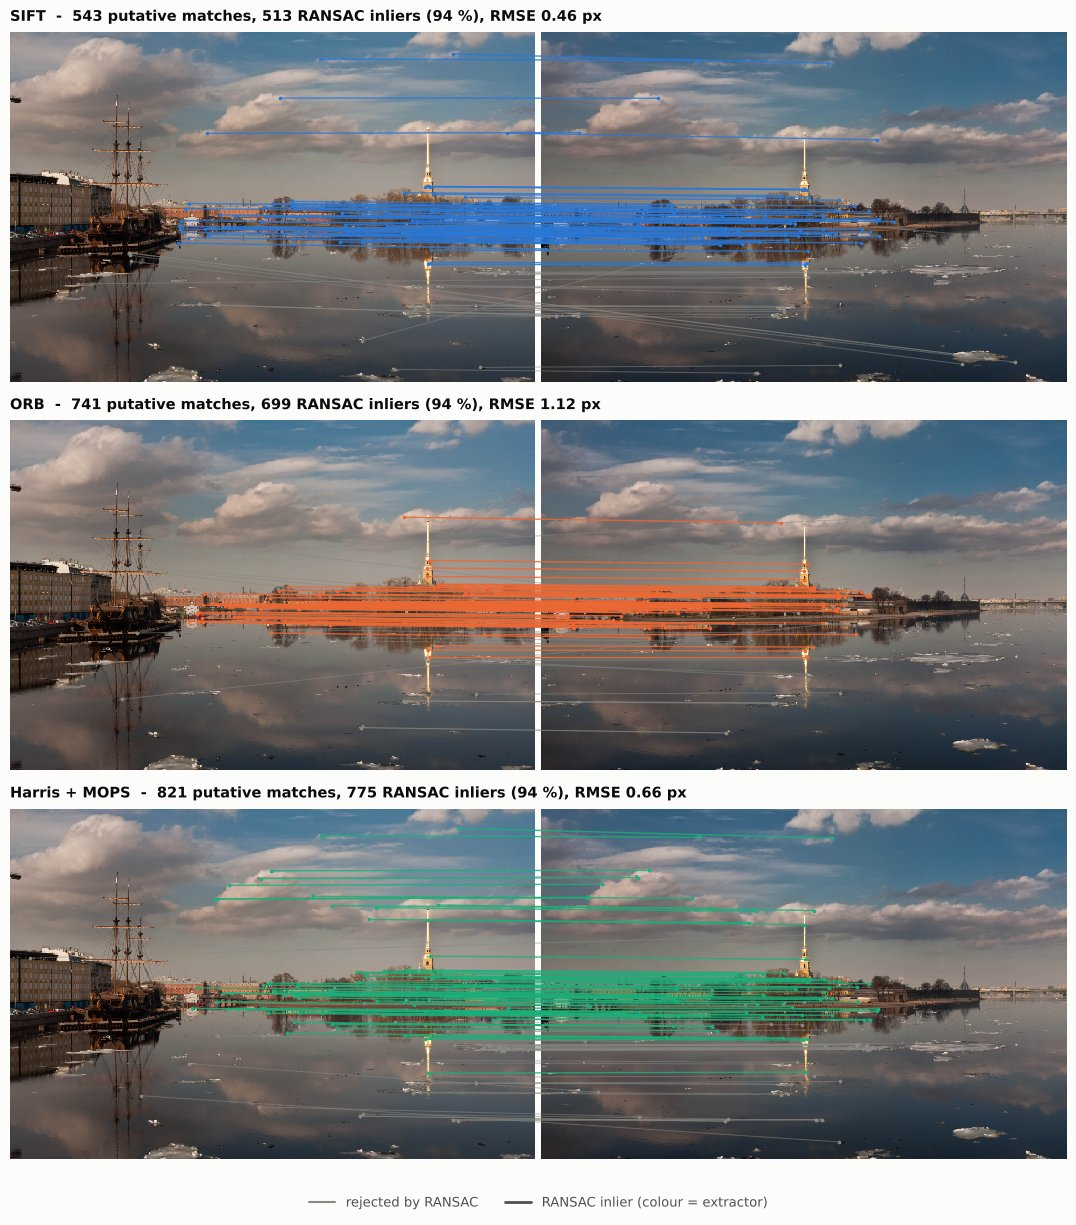

| extractor | keypoints 1 | keypoints 2 | putative matches | inliers | inlier ratio | RANSAC iterations | RMSE before LM (px) | RMSE after LM (px) |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| SIFT (OpenCV) | 1815 | 1328 | 543 | 513 | 0.94 | 8 | 0.465 | 0.465 |
| ORB (OpenCV) | 3954 | 3823 | 741 | 699 | 0.94 | 5 | 1.124 | 1.124 |
| Harris + MOPS (from scratch) | 2286 | 1786 | 821 | 775 | 0.94 | 4 | 0.658 | 0.658 |

In [15]:
pair_data, rows = {}, []
for m in METHODS:
    fa, fb = (detect_and_describe(g, m, 4000) for g in grays[:2])
    mt = match_features(fa, fb)                                                          # ratio test 0.75 + one-to-one
    src, dst = fa.kpts[mt.idx1], fb.kpts[mt.idx2]
    H, inl, info = ransac_homography(src, dst, thresh=3.0, seed=0)
    _, _, info0 = ransac_homography(src, dst, thresh=3.0, seed=0, refine=False)           # same, without the LM polish
    pair_data[m] = dict(pts_a=src, pts_b=dst, inliers=inl, n_matches=len(mt), n_inliers=int(inl.sum()), rmse=info["rmse"])
    rows.append([DESCRIPTIONS[m], len(fa), len(fb), len(mt), int(inl.sum()), f"{inl.mean():.2f}", info["iterations"],
                 f"{info0['rmse']:.3f}", f"{info['rmse']:.3f}"])
show_fig(viz.matches_figure(imgs[0], imgs[1], pair_data, width=11), "jpeg")
table(["extractor", "keypoints 1", "keypoints 2", "putative matches", "inliers", "inlier ratio", "RANSAC iterations", "RMSE before LM (px)", "RMSE after LM (px)"], rows, "lrrrrrrrr")

On real data the polish moves the RMSE by less than 0.01 px: with mild perspective the weights $w_i$ are nearly constant, and the inliers have been selected, so the normalised DLT is already almost the optimum of the geometric error. It is kept because it costs a few milliseconds and guarantees that the result is a minimum of the *right* criterion when the perspective is strong or the matches few. The accuracy that matters comes from the **keypoint localisation** (compare the RMSE of the three extractors above) and from the **inlier selection**.

### ***Which pairs overlap? Three tests***

Not every pair of images of a set overlaps, and RANSAC returns *some* model for any pair. A pair is accepted as overlapping only if

1. it has at least 20 RANSAC inliers;
2. the inliers determine $H$ uniquely: $\sigma_8/\sigma_1\ge10^{-3}$ for their DLT matrix (see the degeneracy argument above);
3. $H$ gives a plausible footprint (`footprint_ok`): no point of the image is sent to infinity (the signs of $\mathbf h_3^\top\mathbf x$ at the four corners agree, so the image of the rectangle is a convex quadrilateral), the orientation is preserved (positive shoelace area, no reflection) and the area changes by less than a factor of 25.

The newspaper scene is the hard case: lines of text repeat. Images 0 and 2 hardly overlap, yet SIFT finds matches between similar letters.

In [16]:
news = preprocess(load_images(list_images(PANO_INPUT_DIR / "newspaper")), 1000)
ng = [cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) for im in news]
fa, fb = detect_and_describe(ng[0], "sift"), detect_and_describe(ng[2], "sift")           # images 0 and 2 hardly overlap

rows = []
for unique in (False, True):
    mt = match_features(fa, fb, ratio=0.75, unique=unique)
    src, dst = fa.kpts[mt.idx1], fb.kpts[mt.idx2]
    H, inl, info = ransac_homography(src, dst, seed=2)
    n_in = int(inl.sum())
    rank = dlt_conditioning(src[inl], dst[inl]) if n_in >= 4 else 0.0
    accepted = n_in >= 20 and rank >= 1e-3
    rows.append(["one-to-one filter" if unique else "plain ratio test", len(mt), len(np.unique(mt.idx2)), n_in,
                 len(np.unique(mt.idx2[inl])), f"{rank:.1e}", "accepted" if accepted else "rejected"])
table(["matching", "matches", "distinct partners in image 2", "RANSAC inliers", "distinct points of image 2 among them", "s8 / s1", "count + rank test"], rows, "lrrrrrl")

| matching | matches | distinct partners in image 2 | RANSAC inliers | distinct points of image 2 among them | s8 / s1 | count + rank test |
| :--- | ---: | ---: | ---: | ---: | ---: | :--- |
| plain ratio test | 194 | 126 | 42 | 1 | 0.0e+00 | rejected |
| one-to-one filter | 126 | 126 | 7 | 7 | 1.5e-04 | rejected |

With the plain ratio test RANSAC finds **42 "inliers" — all of them mapped onto one single keypoint of image 2**. The count alone (42 ≥ 20) would accept the pair; the rank test sees $\sigma_8/\sigma_1 = 0$ and rejects it. With the one-to-one filter the collapsed matches are gone and only 7 inliers remain, which is also a rejection. The three tests are safety nets, not guarantees: the synthetic study at the end counts the pairs that pass them although the geometry is wrong by 3 px or more (*silent failures*).

## **Warping and composition**

### ***Inverse mapping and bilinear interpolation***

*Forward* warping pushes every source pixel to $H\mathbf x$ and leaves holes where the image is magnified and collisions where it is shrunk. *Inverse* warping visits every pixel $\mathbf p$ of the **output** canvas, computes where it comes from, $\mathbf x = H^{-1}\mathbf p$ (one $3\times3$ inverse; one division by the third coordinate per pixel), and **samples the source image** there, so that every output pixel gets exactly one value. A canvas pixel whose source position falls outside $[0,W-1]\times[0,H-1]$ is not covered by this image (mask = False). Source positions are real numbers, so the image must be interpolated. With $x_0=\lfloor x\rfloor$, $a = x - x_0$ (and likewise $y_0$, $b$), one linear interpolation along $x$ in each of the two rows and one along $y$ between the results give

$$f = (1-b)\big[(1-a)f_{00} + a\,f_{10}\big] + b\big[(1-a)f_{01} + a\,f_{11}\big] ,$$

i.e. each of the four neighbours is weighted by the area of the *opposite* sub-rectangle; the weights are non-negative and sum to 1, and any function $\alpha+\beta x+\gamma y+\delta xy$ is reproduced exactly.

### ***The canvas***

The four corners of every image are mapped into the reference frame; the bounding box of all of them is the canvas. A translation $T = \begin{bmatrix}1&0&-x_{\min}\\0&1&-y_{\min}\\0&0&1\end{bmatrix}$ moves it to non-negative coordinates and the final image-to-canvas mapping is $T H_k$. (If a canvas gets absurdly large the projection has exploded: the pipeline reports a degenerate result instead of allocating it.)

### ***From pairs to a panorama: the overlap graph***

The nodes are the images, an edge joins two images that pass the three tests of the previous section, its weight is the number of inliers. Chaining *all* pairwise homographies would accumulate and mix errors. Instead:

1. the **maximum spanning tree** (Kruskal, heaviest edges first, no cycles) keeps the $N-1$ most reliable pairs that connect all images, so every image has exactly one path to the reference;
2. the **reference image** is the centre of the tree (smallest maximum number of hops, ties broken by the inliers): if every hop contributes an independent error of variance $\sigma^2$, an image $k$ hops away has variance $\approx k\sigma^2$, and the centre minimises the worst case;
3. $H_{k\to\text{ref}} = H_{p\to\text{ref}}\,H_{k\to p}$ along the path, where $p$ is the parent of $k$;
4. images without a valid link to the main component are dropped and reported. The order in which the images are given does not matter.

Loop closure (a global bundle adjustment over *all* pairs) is not implemented: the pairs that are not in the tree are only used to decide which pairs overlap.

In [17]:
# bilinear interpolation against OpenCV
rng = np.random.default_rng(0)
g = grays[0].astype(np.float32)
x, y = rng.uniform(0, g.shape[1] - 1, 20000), rng.uniform(0, g.shape[0] - 1, 20000)
ours, valid = bilinear_sample(g, x, y)
ref = cv2.remap(g, x.astype(np.float32)[None, :], y.astype(np.float32)[None, :], cv2.INTER_LINEAR)[0]
print(f"bilinear_sample vs cv2.remap        : max |difference| = {float(np.abs(ours - ref).max()):.1e} grey levels ({int(valid.sum())} samples)")

# inverse warping of image 0 into the frame of image 1, against cv2.warpPerspective
fa, fb = detect_and_describe(grays[0], "sift"), detect_and_describe(grays[1], "sift")
mt = match_features(fa, fb)
H01, inl, _ = ransac_homography(fa.kpts[mt.idx1], fb.kpts[mt.idx2], seed=0)
h1, w1 = imgs[1].shape[:2]
w_ours, m_ours = warp_perspective(imgs[0].astype(np.float32), H01, (h1, w1))
w_cv = cv2.warpPerspective(imgs[0], H01, (w1, h1), flags=cv2.INTER_LINEAR).astype(np.float32)
core = cv2.erode(m_ours.astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool)          # ignore the 2-px border
d = np.abs(w_ours - w_cv).max(axis=2)[core]
print(f"warp_perspective vs cv2.warpPerspective: mean |difference| = {d.mean():.3f}, 99.9 % below {np.percentile(d, 99.9):.2f}, "
      f"max {d.max():.2f} grey levels ({core.sum()} pixels; OpenCV interpolates in fixed point)")

bilinear_sample vs cv2.remap        : max |difference| = 2.4e-03 grey levels (20000 samples)


warp_perspective vs cv2.warpPerspective: mean |difference| = 0.287, 99.9 % below 0.50, max 0.50 grey levels (445080 pixels; OpenCV interpolates in fixed point)


### ***The whole composition on a small scene***

The cathedral scene (3 images) with the three extractors: the footprints of the warped images on the canvas, the spanning tree, and the images warped into the canvas before blending.

SIFT: images used [0, 1, 2] | reference image 1 | spanning tree (i, j, inliers): [(1, 2, 1025), (0, 1, 949)] | canvas (h, w): (910, 1172)


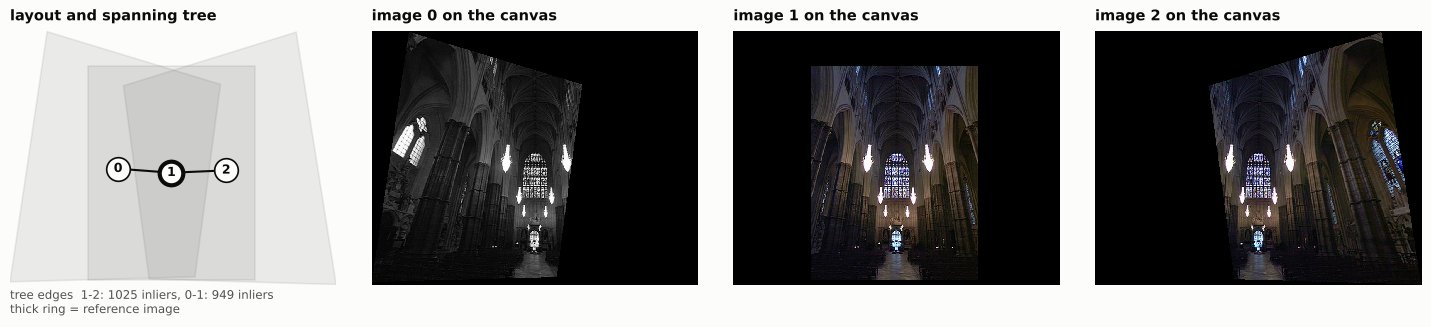

In [18]:
cath = preprocess(load_images(list_images(PANO_INPUT_DIR / "cathedral")), 1000)
results = {m: PanoramaStitcher(StitchConfig(method=m)).stitch(cath, keep_intermediate=True) for m in METHODS}
res = results["sift"]
print("SIFT: images used", res.used, "| reference image", res.root, "| spanning tree (i, j, inliers):", res.tree, "| canvas (h, w):", res.canvas_shape)

n = len(res.used)
fig, axes = plt.subplots(1, 1 + n, figsize=(3.6 * (1 + n), 3.6))
viz.draw_layout(axes[0], res, "layout and spanning tree")
for a, k in enumerate(res.used):
    viz.show_image(axes[1 + a], np.clip(res.warped[a] * 255, 0, 255).astype(np.uint8), f"image {k} on the canvas")
fig.tight_layout()
show_fig(fig, "jpeg")

## **Blending**

After warping, the overlaps contain two (or more) estimates of every pixel. They differ because of (i) residual mis-registration — sub-pixel errors of $H$, lens distortion, parallax — which shows up as *ghosting*, and (ii) different exposure and white balance between the shots, which shows up as a visible *seam*.

| mode | rule | weakness |
| :--- | :--- | :--- |
| overwrite | the last image wins | hard seams (the naive baseline of Part 1) |
| average | mean of the images that cover the pixel | ghosts; the weight jumps at the border of a footprint |
| feather | weights = distance to the border of the image, normalised | one transition width for all frequencies: narrow → exposure seam, wide → ghosting of detail |
| multi-band | Laplacian pyramid blending (Burt & Adelson, 1983) | needs the pyramid machinery; the best compromise |

### ***Multi-band blending for $K$ images***

Part 1 blends *two* images with a mask. Here the operators of Part 1 (`build_gaussian_pyramid`, `build_laplacian_pyramid`, `pyr_up` from `laplacian_blend.py`) are reused for $K$ images:

1. **Partition.** Each canvas pixel is assigned to the image with the largest distance to its own border (a hard mask $M_k\in\{0,1\}$, $\sum_kM_k = 1$ on the covered area).
2. **Pyramids.** Gaussian pyramid of every mask, $G_l(M_k)$, and Laplacian pyramid of every image, $L_l(I_k) = G_l(I_k) - \operatorname{up}(G_{l+1}(I_k))$ (band-pass images; the last level is the low-pass residual).
3. **Blend every band with the mask of its own level**, normalised by the sum of the weights,
$$B_l = \frac{\sum_kG_l(M_k)\,L_l(I_k)}{\sum_kG_l(M_k)} .$$
4. **Collapse**, $I = B_0 + \operatorname{up}\big(B_1 + \operatorname{up}(B_2 + \cdots)\big)$.

Why it works. The Laplacian levels telescope, $I = L_0 + \operatorname{up}(L_1 + \operatorname{up}(L_2+\dots))$, so blending the *bands* and collapsing is a blend of the image. The mask at level $l$ has been blurred by $l$ Gaussian filters, so its transition region is about $2^l$ pixels wide: fine detail (level 0) is switched over within a few pixels — no ghosting — while the low frequencies (exposure, colour) are mixed over a wide zone, hiding the seam. With the same mask at all levels the scheme reduces to feathering. Implementation details that matter: the canvas is padded to a multiple of $2^L$ so every level halves exactly; the pixels an image does not cover are filled with the nearest valid colour inside a margin (otherwise the black background bleeds into the blurred low frequencies and creates dark halos); and the division by $\sum_kG_l(M_k)$ matters near the border of the canvas where the blurred masks do not sum to 1.

### ***Gain compensation (Brown & Lowe, 2007)***

Different exposure is modelled by one multiplicative gain per image, $I_k^{\text{observed}} = g_kI_k$. Let $\bar I_{ij}$ be the mean intensity of image $i$ inside its overlap with image $j$ and $N_{ij}$ the number of pixels of the overlap. The gains minimise

$$e(\mathbf g) = \frac12\sum_{i,j}N_{ij}\left[\frac{(g_i\bar I_{ij} - g_j\bar I_{ji})^2}{\sigma_N^2} + \frac{(1-g_i)^2}{\sigma_g^2}\right],$$

where the first term makes overlapping images agree and the second keeps the gains near 1 (without it $\mathbf g = \mathbf 0$ is a minimiser). $e$ is quadratic in $\mathbf g$. The pair $(i,j)$ and the pair $(j,i)$ both contain $g_k$ when one of them is $k$, so

$$\frac{\partial e}{\partial g_k} = \sum_{j\ne k}N_{kj}\left[\frac{2\,(g_k\bar I_{kj} - g_j\bar I_{jk})\,\bar I_{kj}}{\sigma_N^2} - \frac{1-g_k}{\sigma_g^2}\right] = 0
\;\Longleftrightarrow\;
\sum_{j\ne k}N_{kj}\left[\Big(\frac{2\bar I_{kj}^2}{\sigma_N^2} + \frac1{\sigma_g^2}\Big)g_k - \frac{2\bar I_{kj}\bar I_{jk}}{\sigma_N^2}\,g_j\right] = \sum_{j\ne k}\frac{N_{kj}}{\sigma_g^2},$$

a small linear system $A\mathbf g=\mathbf b$ ($\sigma_N = 10/255$, $\sigma_g = 0.1$ for images in $[0,1]$), which is what `compute_gains` solves. The check below minimises $e$ numerically and compares.

In [19]:
res_boat = PanoramaStitcher(StitchConfig(method="sift")).stitch(imgs, keep_intermediate=True)
print("boat, SIFT: images used", res_boat.used, "| reference", res_boat.root, "| tree", res_boat.tree)

from scipy.optimize import minimize
from panorama.blend import compute_gains

wl, ms = res_boat.warped, res_boat.masks
n = len(wl)
sig_n, sig_g = 10 / 255, 0.1
lum = [im.mean(axis=2) for im in wl]
Nij, Iij = np.zeros((n, n)), np.zeros((n, n))
for i in range(n):
    for j in range(n):
        ov = ms[i] & ms[j]
        if i != j and ov.any():
            Nij[i, j], Iij[i, j] = ov.sum(), lum[i][ov].mean()


def e(g):
    return 0.5 * sum(Nij[i, j] * ((g[i] * Iij[i, j] - g[j] * Iij[j, i]) ** 2 / sig_n ** 2 + (1 - g[i]) ** 2 / sig_g ** 2)
                     for i in range(n) for j in range(n) if i != j)


g_closed = compute_gains(wl, ms)
g_numeric = minimize(e, np.ones(n), method="BFGS", options={"gtol": 1e-6}).x
print("gains from the linear system :", np.round(g_closed, 4))
print("gains from numerical minimum :", np.round(g_numeric, 4), f"(max difference {np.abs(g_closed - g_numeric).max():.1e})")
print(f"e(g = 1) = {e(np.ones(n)):.3e}   e(g*) = {e(g_closed):.3e}")

boat, SIFT: images used [0, 1, 2, 3] | reference 1 | tree [(0, 1, 513), (1, 2, 385), (2, 3, 217)]


gains from the linear system : [0.9191 1.0341 0.9945 1.0317]
gains from numerical minimum : [0.9191 1.0341 0.9945 1.0317] (max difference 2.6e-08)
e(g = 1) = 1.666e+06   e(g*) = 3.876e+05


### ***A controlled test: an exposure gap and a registration error***

Two views of the synthetic world; view 1 is 30 % darker (gain 0.7), and the homography between them is perturbed **on purpose** by a translation of $(3, 2)$ px — a 3.6 px registration error, bigger than what the pipeline produces but typical of parallax or lens distortion near the border of an image. The same views are blended with every mode. *Sharpness* is the mean gradient magnitude of the luminance in the core of the overlap (grey levels per pixel): ghosting averages two displaced copies of every edge and lowers it, so the loss of sharpness caused by the registration error measures how well a blender hides the error. (The absolute level depends on the brightness of the images that contribute — the gains rescale the gradients too — so compare every blender with itself, in the last column.)

| blender | sharpness, exact registration | sharpness, 3.6 px error | change |
| :--- | ---: | ---: | ---: |
| overwrite | 3.29 | 3.29 | +0.1 % |
| average | 2.67 | 2.05 | -23.1 % |
| feather | 2.69 | 2.16 | -19.5 % |
| multiband | 2.75 | 2.71 | -1.6 % |
| multiband + gain | 2.58 | 2.56 | -0.6 % |

exact registration: mean |luminance difference| inside the overlap  37.2 grey levels without,   6.9 with gain compensation (gains [0.836 1.115])
3.6 px error      : mean |luminance difference| inside the overlap  37.7 grey levels without,   9.6 with gain compensation (gains [0.837 1.115])


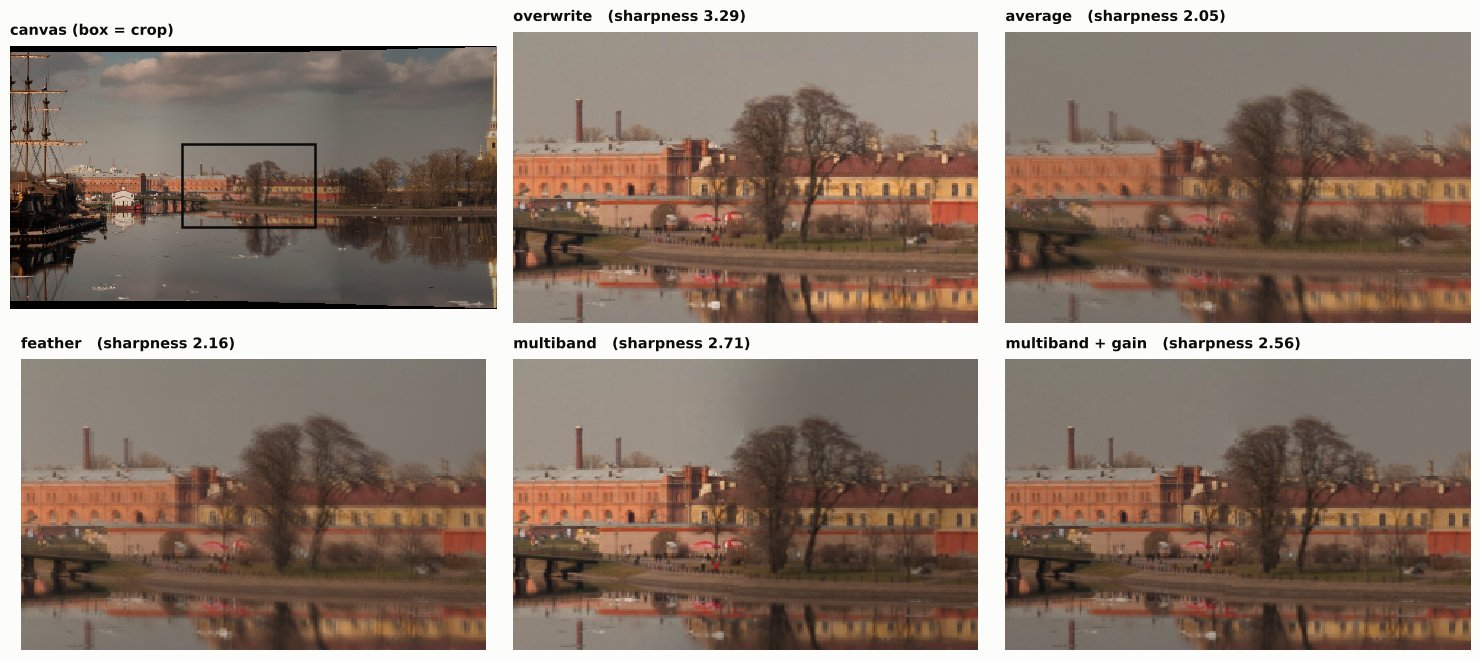

In [20]:
from panorama.blend import blend_images
from panorama.warp import compute_canvas
from panorama.metrics import overlap_photometric_error

sv, Hs, _ = render_views(world, [ViewSpec(yaw=-5), ViewSpec(yaw=5, gain=0.7)], size=(800, 600))      # view 1 is 30 % darker
MODES = [("overwrite", "overwrite", False), ("average", "average", False), ("feather", "feather", False),
         ("multiband", "multiband", False), ("multiband + gain", "multiband", True)]


def stress(shift):
    # warp both views onto one canvas, with an extra translation `shift` (px) of view 1, and blend them in every mode
    H10 = np.array([[1, 0, shift[0]], [0, 1, shift[1]], [0, 0, 1.0]]) @ Hs[(1, 0)]                       # view 1 -> view 0
    Hs_ = [np.eye(3), H10]
    (hc, wc), T = compute_canvas([v.shape[:2] for v in sv], Hs_, max_side=None)
    ims, msk = [], []
    for v_, H_ in zip(sv, Hs_):
        w_, m_ = warp_perspective(v_.astype(np.float32) / 255, T @ H_, (hc, wc))
        ims.append(w_); msk.append(m_)
    core = cv2.erode((msk[0] & msk[1]).astype(np.uint8), np.ones((41, 41), np.uint8)).astype(bool)        # core of the overlap
    out = {}
    for label, mode, use_gain in MODES:
        pano, _, _ = blend_images(ims, msk, mode, 5, [1, 0], gain_compensation=use_gain)
        gy_, gx_ = np.gradient(pano.mean(axis=2))
        out[label] = (pano, 255 * np.hypot(gx_, gy_)[core].mean())                                       # sharpness
    return out, core, ims, msk


exact, _, ims_ex, msk_ex = stress((0.0, 0.0))
bad, core, ims_bad, msk_bad = stress((3.0, 2.0))
table(["blender", "sharpness, exact registration", "sharpness, 3.6 px error", "change"],
      [[label, f"{exact[label][1]:.2f}", f"{bad[label][1]:.2f}", f"{100 * (bad[label][1] / exact[label][1] - 1):+.1f} %"] for label, _, _ in MODES], "lrrr")

for name_, (ims_, msk_) in (("exact registration", (ims_ex, msk_ex)), ("3.6 px error", (ims_bad, msk_bad))):
    g_ = compute_gains(ims_, msk_)
    mae0 = overlap_photometric_error(ims_[0], msk_[0], ims_[1], msk_[1])["mae"]
    mae1 = overlap_photometric_error(ims_[0] * g_[0], msk_[0], ims_[1] * g_[1], msk_[1])["mae"]
    print(f"{name_:18s}: mean |luminance difference| inside the overlap {mae0:5.1f} grey levels without, {mae1:5.1f} with gain compensation (gains {np.round(g_, 3)})")

# crops around the strongest horizontal structure of the overlap
edge = np.abs(np.diff(ims_bad[0].mean(axis=2), axis=0, prepend=ims_bad[0].mean(axis=2)[:1])) * core
cy, cx = int(np.argmax(edge.sum(axis=1))), int(np.median(np.nonzero(core)[1]))
y0, x0 = cy - 100, cx - 160
fig, axes = plt.subplots(2, 3, figsize=(15, 6.6))
for ax in axes.ravel():
    ax.set_axis_off()
over = np.clip(bad["feather"][0] * 255, 0, 255).astype(np.uint8)
viz.show_image(axes[0, 0], over, "canvas (box = crop)")
axes[0, 0].add_patch(plt.Rectangle((x0, y0), 320, 200, fill=False, ec=viz.INK, lw=1.8))
for ax, (label, _, _) in zip(axes.ravel()[1:], MODES):
    viz.show_image(ax, np.clip(bad[label][0][y0:y0 + 200, x0:x0 + 320] * 255, 0, 255).astype(np.uint8), f"{label}   (sharpness {bad[label][1]:.2f})")
fig.tight_layout(h_pad=2.4, w_pad=0.4)
show_fig(fig, "jpeg")

**Reading the result.** With the registration error, averaging and feathering lose a fifth to a quarter of their sharpness (−23 %, −20 %): every edge appears twice, like the double branches of the tree in the crops. Overwrite keeps its sharpness — each pixel comes from one image — but leaves a hard seam. Multi-band blending loses less than 2 %, because its fine bands switch from one image to the other within a few pixels, so each edge comes from *one* image. The price is visible in the multi-band crop without gain compensation: its low-frequency band mixes the two exposures over a wide zone, which hides the *seam* but not the *difference*, a soft darker area remains on the side of view 1. The gain compensation removes it: the mean luminance difference inside the overlap drops from 37 to 7 grey levels (to 10 with the registration error; not to zero, because the prior $\sigma_g$ keeps the gains close to 1 — the estimated gains 0.84 and 1.12 differ by a factor 1.33, the true ratio is 1/0.7 = 1.43), and the sharpness does not suffer (−0.6 %). This is why the full pipeline offers `blend="multiband"` and `gain_compensation=True`.

### ***The blending modes side by side***

A crop around the overlap of the best-overlapping pair of the boat scene. The number under each crop is the mean luminance difference of the two warped images inside the overlap: it only changes with the gain compensation (the other modes blend, they do not equalise).

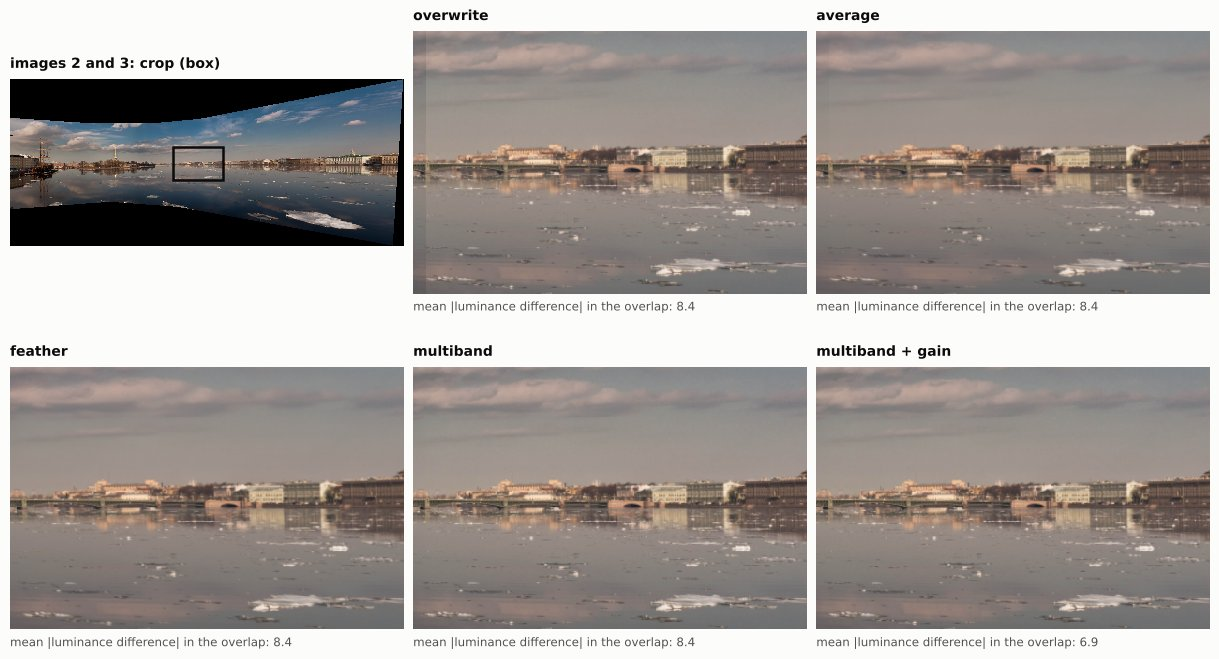

In [21]:
show_fig(viz.blend_comparison_figure(res_boat), "jpeg")

## **The complete pipeline**

`PanoramaStitcher` runs all the stages above. The extractor is the only thing that changes between the three panoramas below (same matching, RANSAC, warping and blending code):

```python
from panorama import PanoramaStitcher, StitchConfig, load_images

result = PanoramaStitcher(StitchConfig(method="orb", blend="multiband", gain_compensation=True)).stitch(load_images(paths))
cv2.imwrite("panorama.jpg", result.panorama)       # result also holds the homographies, matches, inliers, timings, ...
```

or from the shell: `python run_panorama.py --scene boat --method sift`, `python run_panorama.py --folder my_photos --compare` (all extractors, one table).

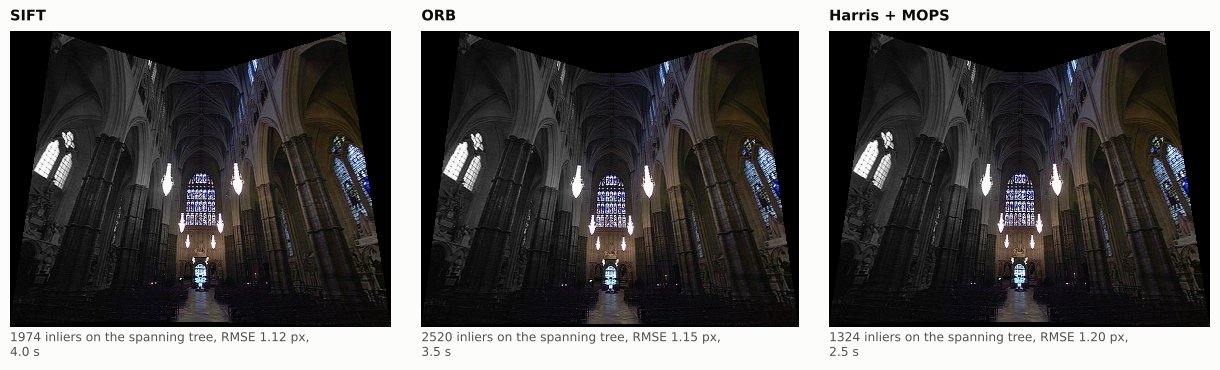

| extractor | pair | putative matches | inliers | inlier ratio | RMSE (px) | s8 / s1 | accepted |
| :--- | :--- | ---: | ---: | ---: | ---: | ---: | :--- |
| SIFT (OpenCV) | 0 - 1 | 1055 | 949 | 0.90 | 1.10 | 2.6e-01 | yes |
| SIFT (OpenCV) | 0 - 2 | 693 | 585 | 0.84 | 1.04 | 1.8e-01 | yes |
| SIFT (OpenCV) | 1 - 2 | 1155 | 1025 | 0.89 | 1.14 | 2.5e-01 | yes |
| ORB (OpenCV) | 0 - 1 | 1229 | 1187 | 0.97 | 1.13 | 1.4e-01 | yes |
| ORB (OpenCV) | 0 - 2 | 1233 | 1183 | 0.96 | 1.23 | 1.2e-01 | yes |
| ORB (OpenCV) | 1 - 2 | 1390 | 1333 | 0.96 | 1.18 | 1.5e-01 | yes |
| Harris + MOPS (from scratch) | 0 - 1 | 690 | 638 | 0.92 | 1.19 | 2.2e-01 | yes |
| Harris + MOPS (from scratch) | 0 - 2 | 433 | 373 | 0.86 | 1.02 | 1.4e-01 | yes |
| Harris + MOPS (from scratch) | 1 - 2 | 754 | 686 | 0.91 | 1.21 | 2.2e-01 | yes |

In [22]:
panos = {m: results[m].panorama for m in METHODS}                                  # the cathedral scene stitched above
caps = {m: f"{viz.SERIES[m]['label']}\n{sum(w for _, _, w in results[m].tree)} inliers on the spanning tree, "
           f"RMSE {np.mean([results[m].pairs[(i, j)].rmse for i, j, _ in results[m].tree]):.2f} px, "
           f"{results[m].timings['total']:.1f} s" for m in METHODS}
show_fig(viz.panorama_figure(panos, caps), "jpeg")

rows = []
for m in METHODS:
    for (i, j), p in results[m].pairs.items():
        rows.append([DESCRIPTIONS[m], f"{i} - {j}", p.n_matches, p.n_inliers, f"{p.inlier_ratio:.2f}", f"{p.rmse:.2f}", f"{p.rank_ratio:.1e}", "yes" if p.valid else "no"])
table(["extractor", "pair", "putative matches", "inliers", "inlier ratio", "RMSE (px)", "s8 / s1", "accepted"], rows, "llrrrrrl")

The three panoramas are practically identical; what differs is how the geometry was obtained (inliers, RMSE, time). One thing in the picture is a property of the *data*, not of the method: the first photograph of this set is a greyscale image (its three channels are equal) while the other two are in colour, so the colour fades towards the part of the panorama that comes from it. The extractors only look at the luminance and are not affected.

## **Experiments**

Two kinds of experiments answer different questions.

1. **Real scenes** (5 scenes, 2–4 images each, 3 extractors, default parameters). There is no ground truth, so the pairwise geometry is judged by the RANSAC statistics (inlier ratio, RMS reprojection error of the inliers) and the final alignment by the agreement of the warped images inside their overlaps: the zero-mean normalised cross-correlation of the high-pass filtered luminance (1 = perfect, it reacts to ghosting) and the mean absolute difference in grey levels (it also reacts to exposure differences and parallax, so it is a property of the scene as much as of the extractor).
2. **Controlled synthetic study** with *exact* ground truth (`synthetic.py`, `scripts/run_synthetic.py`). Two views of a photograph are rendered by rotating a virtual camera; **one** difficulty factor is changed at a time — overlap (angle between the views), in-plane roll, zoom, Gaussian noise, exposure, blur — while the others stay comfortable. A trial is a *success* if the pair is accepted by the three tests **and** the estimated homography is within 3 px (RMS over the overlap) of the true one; each level has 30 trials; the *limit* of an extractor on a factor is the hardest level that is still solved in at least 90 % of the trials. The study (≈ 3 × 1050 trials) is run by the script, the stored results are read here.

### ***Real scenes***

Real scenes, multi-band blending, default parameters.  inliers = RANSAC inliers on the pairs of the spanning tree, ratio = inliers / putative matches, RMSE = RMS reprojection error of the inliers (px), NCC / MAE = agreement of the warped images inside their overlaps (high-pass NCC: 1 is perfect; MAE in grey levels).

| scene | extractor | keypoints / image | inliers | ratio | RMSE px | NCC high-pass | MAE | time s |
| :--- | :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| aqueduct | SIFT | 4000 | 1688 | 0.99 | 0.24 | 0.950 | 4.4 | 1.9 |
| aqueduct | ORB | 4000 | 1062 | 0.95 | 0.97 | 0.947 | 4.5 | 1.5 |
| aqueduct | Harris + MOPS | 4000 | 1472 | 0.99 | 0.55 | 0.950 | 4.4 | 2.7 |
| boat | SIFT | 1436 | 1115 | 0.88 | 0.52 | 0.763 | 10.6 | 13.1 |
| boat | ORB | 3833 | 2044 | 0.89 | 1.09 | 0.743 | 10.4 | 13.3 |
| boat | Harris + MOPS | 1889 | 1828 | 0.90 | 0.77 | 0.735 | 10.2 | 12.7 |
| cathedral | SIFT | 3778 | 1974 | 0.89 | 1.12 | 0.739 | 8.7 | 3.0 |
| cathedral | ORB | 3828 | 2520 | 0.96 | 1.15 | 0.776 | 9.5 | 2.8 |
| cathedral | Harris + MOPS | 1635 | 1324 | 0.92 | 1.20 | 0.734 | 8.9 | 2.5 |
| mountain | SIFT | 1924 | 164 | 0.82 | 1.06 | 0.788 | 19.9 | 1.8 |
| mountain | ORB | 3840 | 307 | 0.89 | 1.29 | 0.761 | 20.0 | 1.9 |
| mountain | Harris + MOPS | 1454 | 269 | 0.92 | 1.15 | 0.779 | 19.9 | 1.6 |
| newspaper | SIFT | 4000 | 3305 | 0.89 | 0.32 | 0.927 | 7.4 | 6.3 |
| newspaper | ORB | 4000 | 2485 | 0.90 | 0.89 | 0.905 | 7.9 | 5.4 |
| newspaper | Harris + MOPS | 4000 | 4310 | 0.98 | 0.49 | 0.925 | 7.4 | 8.2 |

Mean over the scenes:

| extractor | keypoints / image | ratio | RMSE px | NCC high-pass | MAE | time s |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| SIFT | 3028 | 0.89 | 0.65 | 0.833 | 10.2 | 5.2 |
| ORB | 3900 | 0.92 | 1.08 | 0.826 | 10.5 | 5.0 |
| Harris + MOPS | 2596 | 0.94 | 0.83 | 0.825 | 10.2 | 5.6 |

Time per stage (ms, mean over all scenes): SIFT: features/image 144, matching/pair 91, RANSAC/pair 43; ORB: features/image 18, matching/pair 151, RANSAC/pair 29; Harris + MOPS: features/image 297, matching/pair 70, RANSAC/pair 30


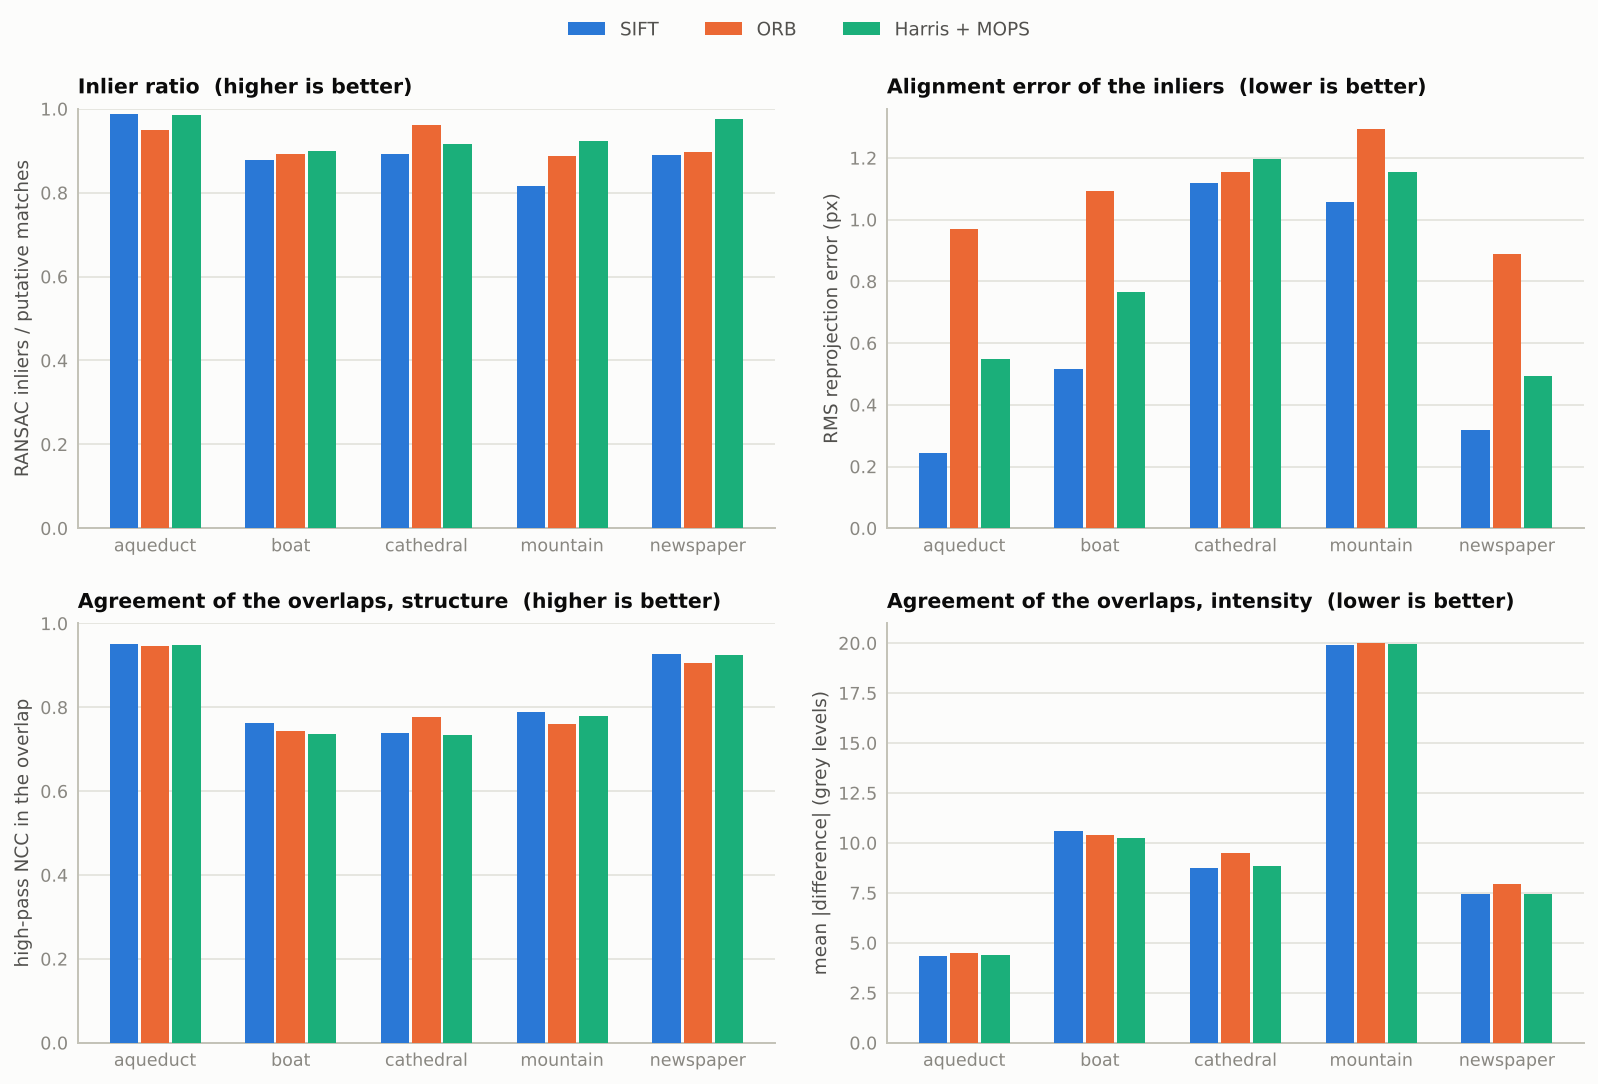

In [23]:
res_dir = PANO_RESULT_DIR
display(Markdown((res_dir / "scenes_summary.md").read_text()))
display(Image(filename=str(res_dir / "figures" / "scenes_metrics.png")))

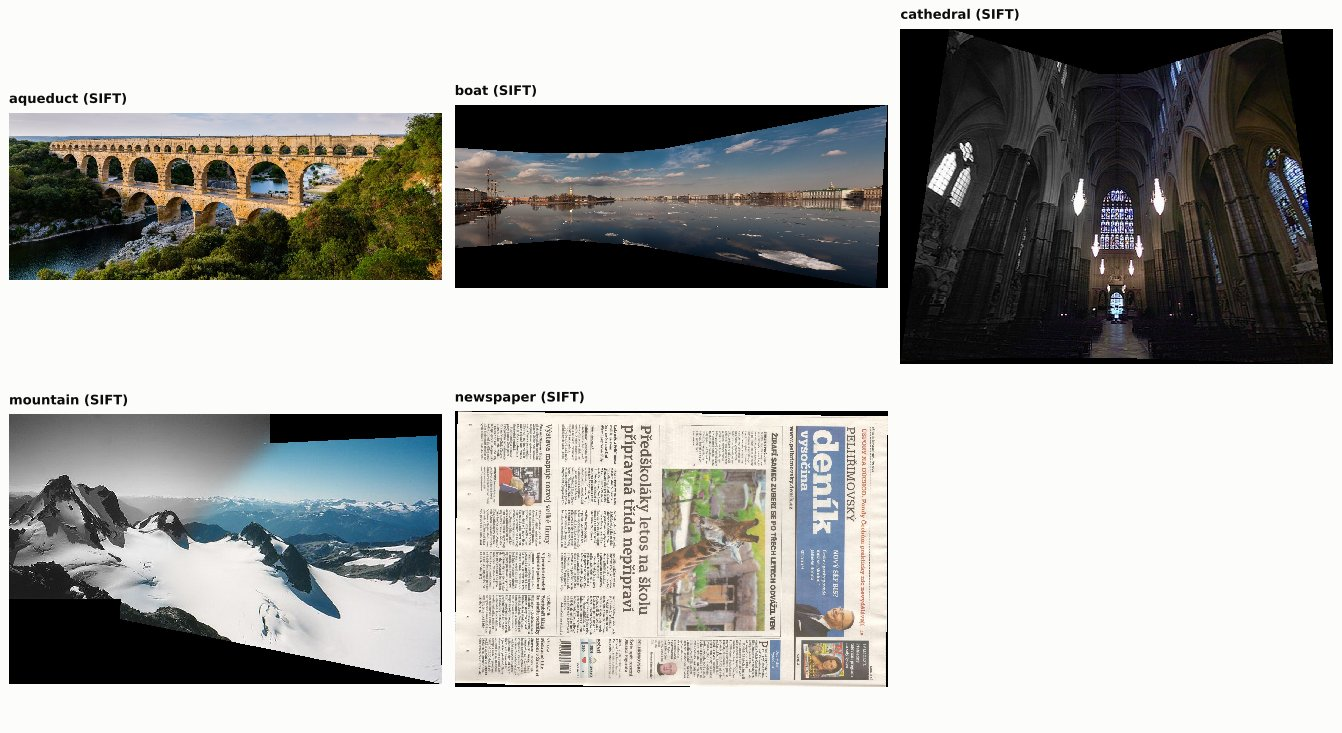

In [24]:
scenes = ["aqueduct", "boat", "cathedral", "mountain", "newspaper"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8.2))
for ax in axes.ravel():
    ax.set_axis_off()
for ax, s in zip(axes.ravel(), scenes):
    viz.show_image(ax, cv2.imread(str(res_dir / s / f"{s}_sift.jpg")), f"{s} (SIFT)")
fig.tight_layout()
show_fig(fig, "jpeg", dpi=90)

In [25]:
# where do two images of a scene agree?  High-pass NCC inside six horizontal bands of the overlap (top to bottom)
from panorama.metrics import overlap_ncc_bands, overlap_photometric_error
from panorama.blend import compute_gains

res_news = PanoramaStitcher(StitchConfig(method="sift")).stitch(load_images(list_images(PANO_INPUT_DIR / "newspaper")), keep_intermediate=True)
for name, r_ in (("boat", res_boat), ("newspaper", res_news)):
    pos = {k: a for a, k in enumerate(r_.used)}
    rows = []
    for i, j, _ in r_.tree:
        a_, b_ = pos[i], pos[j]
        bands = overlap_ncc_bands(r_.warped[a_], r_.masks[a_], r_.warped[b_], r_.masks[b_])
        rows.append([f"{i} - {j}"] + [f"{v:.2f}" for v in bands])
    print(f"{name} (SIFT): high-pass NCC inside six horizontal bands of the overlap, top to bottom")
    table(["pair"] + [f"band {k}" for k in range(1, 7)], rows, "l" + "r" * 6)

# which photographs are greyscale (three equal channels)?
rows = []
for s_ in scenes:
    flags = ["grey" if (im[..., 0] == im[..., 1]).all() and (im[..., 1] == im[..., 2]).all() else "colour"
             for im in load_images(list_images(PANO_INPUT_DIR / s_))]
    rows.append([s_, ", ".join(flags)])
table(["scene", "photographs in file order"], rows, "ll")

# the mountain pair: how much of the intensity gap can a gain per image remove?
res_mtn = PanoramaStitcher(StitchConfig(method="sift")).stitch(load_images(list_images(PANO_INPUT_DIR / "mountain")), keep_intermediate=True)
g_ = compute_gains(res_mtn.warped, res_mtn.masks)
before = overlap_photometric_error(res_mtn.warped[0], res_mtn.masks[0], res_mtn.warped[1], res_mtn.masks[1])["mae"]
after = overlap_photometric_error(res_mtn.warped[0] * g_[0], res_mtn.masks[0], res_mtn.warped[1] * g_[1], res_mtn.masks[1])["mae"]
print(f"mountain: mean |luminance difference| in the overlap {before:.1f} grey levels, {after:.1f} after gain compensation (gains {np.round(g_, 3)})")

boat (SIFT): high-pass NCC inside six horizontal bands of the overlap, top to bottom


| pair | band 1 | band 2 | band 3 | band 4 | band 5 | band 6 |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| 0 - 1 | 0.86 | 0.90 | 0.95 | 0.91 | 0.28 | 0.00 |
| 1 - 2 | 0.79 | 0.91 | 0.95 | 0.90 | 0.30 | -0.05 |
| 2 - 3 | -0.07 | -0.04 | 0.85 | 0.87 | 0.75 | 0.89 |

newspaper (SIFT): high-pass NCC inside six horizontal bands of the overlap, top to bottom


| pair | band 1 | band 2 | band 3 | band 4 | band 5 | band 6 |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| 2 - 3 | 0.94 | 0.96 | 0.94 | 0.93 | 0.93 | 0.93 |
| 0 - 1 | 0.92 | 0.97 | 0.97 | 0.97 | 0.94 | 0.94 |
| 1 - 2 | 0.91 | 0.93 | 0.91 | 0.92 | 0.86 | 0.87 |

| scene | photographs in file order |
| :--- | :--- |
| aqueduct | colour, colour |
| boat | colour, colour, colour, colour |
| cathedral | grey, colour, colour |
| mountain | grey, colour |
| newspaper | colour, colour, colour, colour |

mountain: mean |luminance difference| in the overlap 19.9 grey levels, 17.1 after gain compensation (gains [1.035 0.963])


### ***Reading the real-scene results***

**Geometry.** SIFT has the smallest RMS reprojection error of the inliers in every scene (mean 0.65 px, against 0.83 px for Harris + MOPS and 1.08 px for ORB): by a wide margin in the sharp, high-resolution sets (aqueduct, boat, newspaper) and by only 0.03-0.24 px in the small, soft cathedral and mountain images. That is what the way the keypoints are localised predicts: SIFT fits a quadratic to the DoG scale space (sub-pixel in $x$, $y$ and scale), Harris + MOPS fits a parabola to the corner response of its pyramid level, ORB reports FAST corners at *integer* positions of its pyramid level, so its error grows with the level. The inlier *ratio* (how clean the putative matches are) ranks the extractors differently: Harris + MOPS has the highest ratio in three scenes and on average (0.94, against 0.92 for ORB and 0.89 for SIFT) — a clean set of matches is not the same as exact positions.

**Overlap agreement.** After blending, the extractors can hardly be told apart: the high-pass NCC of the overlaps differs by at most 0.05 between them in every scene and the MAE by less than one grey level. What these two numbers measure is mostly the scene.

* The newspaper — a plane, for which a homography is exact whatever the camera motion — and the aqueduct reach 0.91–0.95.
* The boat set stays at 0.74-0.76, which is *not* a single registration error; the two cells below take it apart. In the overlaps of pairs 0-1 and 1-2 the upper bands (clouds, skyline) correlate at 0.79-0.95 with no shift needed, while the two bottom bands, which show the water with floating ice, collapse and are not rescued by any shift of up to 12 px: the ice and the ripples moved between the shots. Pair 2-3 is different: its water correlates, but its two sky bands do not, and a shift of about 8 px restores part of the correlation - the homography is extrapolated badly where no inlier supports it. The newspaper is high in every band.
* In the mountain and the cathedral sets the first photograph is **greyscale** (three equal channels, table) and the others are in colour; their tonal rendering also differs (the sky of the grey mountain photograph is much lighter than the blue sky of its neighbour). The MAE of about 20 grey levels of the mountain scene is therefore a property of the input — a gain per image can only scale an image, and removes only a part of the gap (see the printout) — and both panoramas show a transition from grey to colour. The extractors see only the luminance, so the geometry is estimated as usual (164–307 inliers at a ratio of 0.82–0.92 in the mountain scene).

### ***Content or registration? Two diagnostics***

A low NCC in a band can have two causes that need different remedies: the **content changed** between the exposures (water, ice, leaves - no shift of the image restores the correlation), or the **registration is off** there (a homography is only as good as the matches that determined it, and it is extrapolated into regions no match covers - a small shift restores part of the correlation). `scripts/analyse_overlap_bands.py` tells them apart: it repeats the six-band comparison after shifting the second image by up to +-12 px, reports the best correlation and the shift that gives it, and says where the RANSAC inliers lie. `scripts/analyse_chain_drift.py` measures how much error the chaining of homographies accumulates: a pair that overlaps but is not an edge of the spanning tree has its own homography, which must agree with the chain through the tree. Both scripts write the tables read below.

**Boat (SIFT), shifts of up to 12 px.** In pairs 0-1 and 1-2 the four upper bands are exactly registered (best shift (0, 0)) and the two lower bands - water with floating ice - are not rescued by any shift (best NCC 0.12-0.46): the content changed. In pair 2-3 the water correlates (0.75-0.89) and the two sky bands do not (-0.07, -0.04); shifting the image by (-7, -4) px restores part of it (0.52 in band 2). This is not a smooth sky: the top band of pair 1-2 has the same high-pass standard deviation (1.9 against 1.8 grey levels) and correlates at 0.79. What differs is where the matches are: 95 % of the inliers of pair 2-3 lie in the lower half of the overlap (from 48 % of its height down), so the sky is far from every constraint. The data fit a homography that is extrapolated badly where no inlier supports it; they do not exclude that the clouds moved between the shots.

**Chaining.** On the planar newspaper the chain agrees with the direct estimate to 0.08-0.26 px. On the three-dimensional boat and cathedral sets the disagreement is 0.6-3.7 px RMS (up to 12 px at the corners) when the direct pair has plenty of inliers; the boat pair 1-3 has only 30-31 inliers on 14 % of the area, and there the direct estimate of SIFT (12.9 px) is probably the unreliable side, not the chain (Harris + MOPS: 1.8 px). Nothing corrects this drift: there is no bundle adjustment and no loop closure.

In [26]:
display(Markdown((PANO_RESULT_DIR / "overlap_bands_boat_sift.md").read_text(encoding="utf-8")))
display(Markdown((PANO_RESULT_DIR / "chain_drift.md").read_text(encoding="utf-8")))

# Overlap bands of 'boat' (sift), shifts searched: +-12 px

## pair 0-1: 513 inliers, overlap rows 380..1028 of the canvas

RANSAC inliers: rows at the 5th / 50th / 95th percentile = 645 / 731 / 780 (= 41 % / 54 % / 62 % of the height of the overlap, from the top); 21 % of the height lies between the 5th and the 95th.

| band | pixels | sigma A | sigma B | NCC | best NCC | shift (dx, dy) px |
|--:|--:|--:|--:|--:|--:|:--:|
| 1 | 66280 | 2.8 | 3.4 | 0.86 | 0.86 | (+0, +0) |
| 2 | 71897 | 3.0 | 3.9 | 0.90 | 0.90 | (+0, +0) |
| 3 | 71933 | 5.7 | 7.5 | 0.95 | 0.95 | (+0, +0) |
| 4 | 72036 | 13.1 | 15.8 | 0.91 | 0.91 | (+0, +0) |
| 5 | 72078 | 6.2 | 7.6 | 0.28 | 0.32 | (+0, +1) |
| 6 | 69526 | 3.3 | 2.7 | 0.00 | 0.12 | (+7, -7) |

## pair 1-2: 385 inliers, overlap rows 380..1028 of the canvas

RANSAC inliers: rows at the 5th / 50th / 95th percentile = 560 / 722 / 773 (= 28 % / 53 % / 61 % of the height of the overlap, from the top); 33 % of the height lies between the 5th and the 95th.

| band | pixels | sigma A | sigma B | NCC | best NCC | shift (dx, dy) px |
|--:|--:|--:|--:|--:|--:|:--:|
| 1 | 55119 | 1.9 | 2.0 | 0.79 | 0.79 | (+0, +0) |
| 2 | 65111 | 4.2 | 3.9 | 0.91 | 0.91 | (+0, +0) |
| 3 | 65002 | 7.5 | 7.0 | 0.95 | 0.95 | (+0, +0) |
| 4 | 64894 | 12.8 | 12.4 | 0.90 | 0.90 | (+0, +0) |
| 5 | 64785 | 9.1 | 8.5 | 0.30 | 0.46 | (-7, +1) |
| 6 | 64311 | 5.7 | 4.7 | -0.05 | 0.22 | (-12, +5) |

## pair 2-3: 217 inliers, overlap rows 320..1103 of the canvas

RANSAC inliers: rows at the 5th / 50th / 95th percentile = 700 / 723 / 1052 (= 48 % / 51 % / 93 % of the height of the overlap, from the top); 45 % of the height lies between the 5th and the 95th.

| band | pixels | sigma A | sigma B | NCC | best NCC | shift (dx, dy) px |
|--:|--:|--:|--:|--:|--:|:--:|
| 1 | 56811 | 1.8 | 1.7 | -0.07 | 0.13 | (-8, -9) |
| 2 | 82016 | 3.1 | 3.0 | -0.04 | 0.52 | (-7, -4) |
| 3 | 80587 | 6.3 | 6.0 | 0.85 | 0.88 | (-1, +0) |
| 4 | 80395 | 10.4 | 9.6 | 0.87 | 0.87 | (+0, +0) |
| 5 | 79579 | 4.4 | 4.1 | 0.75 | 0.75 | (+0, +0) |
| 6 | 63857 | 4.5 | 4.6 | 0.89 | 0.89 | (+0, +0) |


# Drift of the chained homographies against independently estimated pairs

| scene | extractor | pair | tree edges between them | share of image i inside j | inliers | RMS drift (px) | max drift (px) |
|:--|:--|:--:|--:|--:|--:|--:|--:|
| boat | sift | 0-2 | 2 | 32 % | 256 | 0.65 | 1.23 |
| boat | sift | 1-3 | 2 | 14 % | 30 | 12.85 | 28.09 |
| boat | orb | 0-2 | 2 | 31 % | 270 | 1.88 | 5.52 |
| boat | harris | 0-2 | 2 | 31 % | 350 | 0.69 | 1.83 |
| boat | harris | 1-3 | 2 | 14 % | 31 | 1.84 | 3.76 |
| cathedral | sift | 0-2 | 2 | 45 % | 585 | 2.83 | 5.94 |
| cathedral | orb | 0-2 | 2 | 45 % | 1183 | 0.62 | 2.13 |
| cathedral | harris | 0-2 | 2 | 44 % | 373 | 3.72 | 12.19 |
| newspaper | sift | 1-3 | 2 | 35 % | 587 | 0.08 | 0.18 |
| newspaper | orb | 1-3 | 2 | 35 % | 579 | 0.26 | 0.69 |
| newspaper | harris | 1-3 | 2 | 35 % | 714 | 0.10 | 0.28 |


### ***Controlled study with ground truth***

Share of correct homographies (left to right: harder), the error of the correct ones, and how many RANSAC inliers survive. The numbers behind the curves are in `data/panorama/result/synthetic/summary.md` and `summary.csv`.

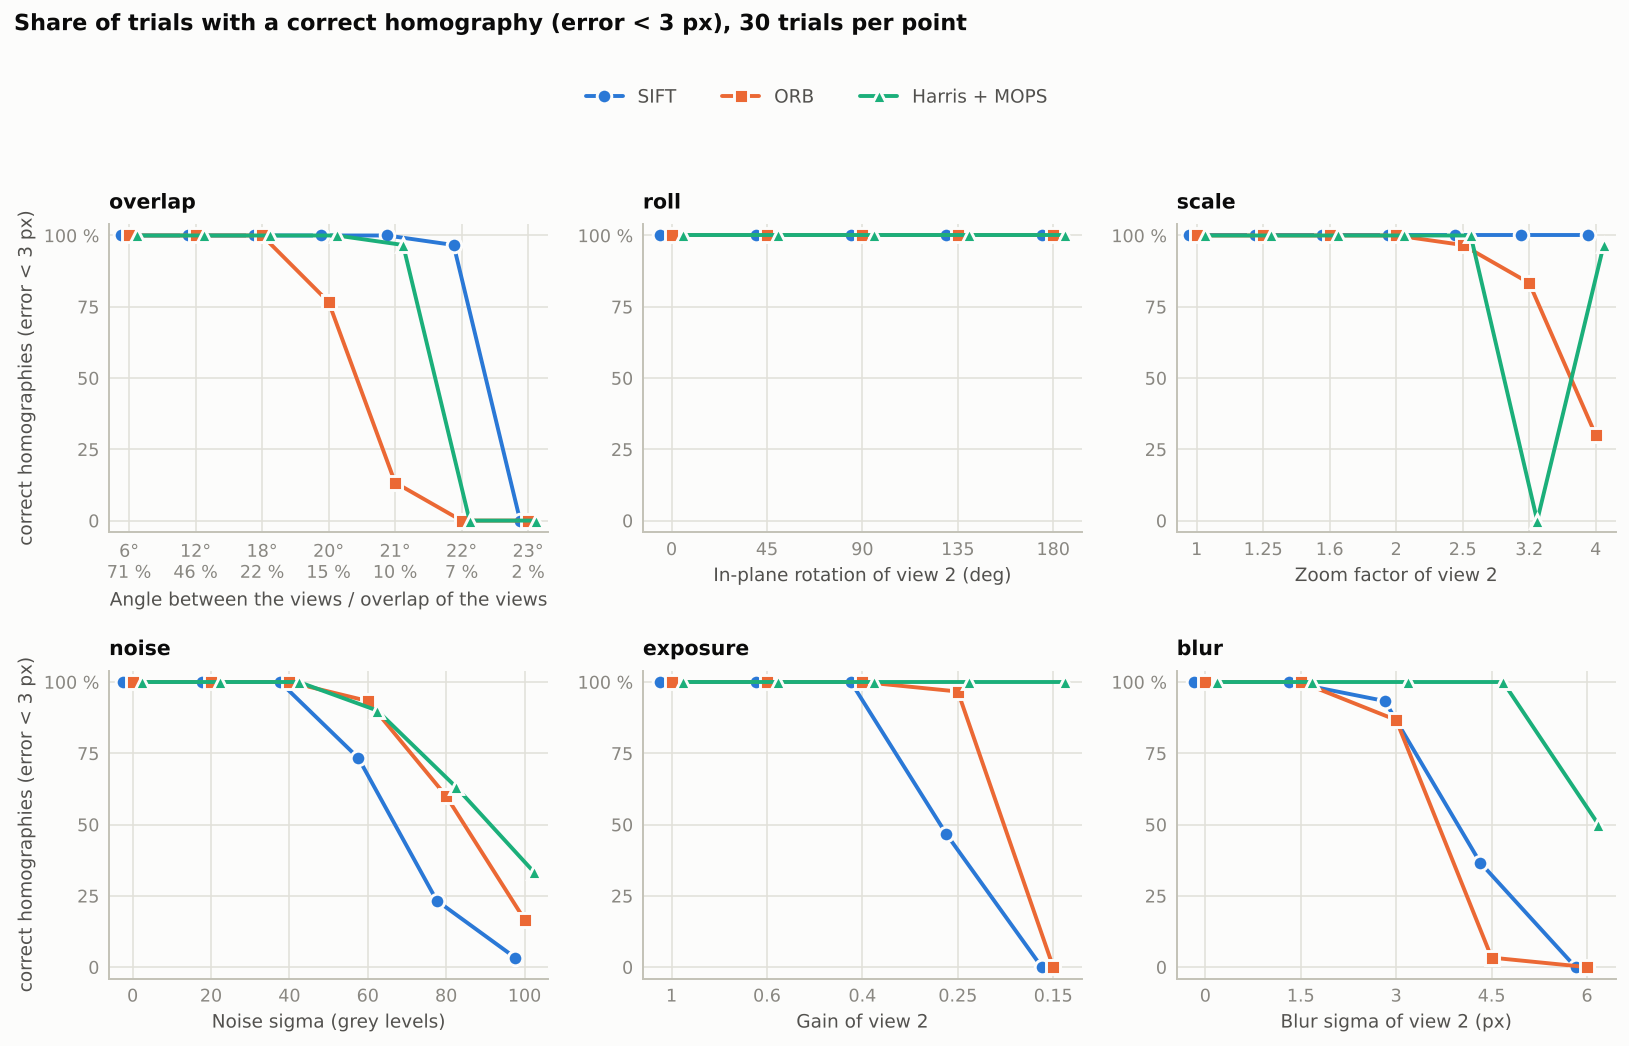

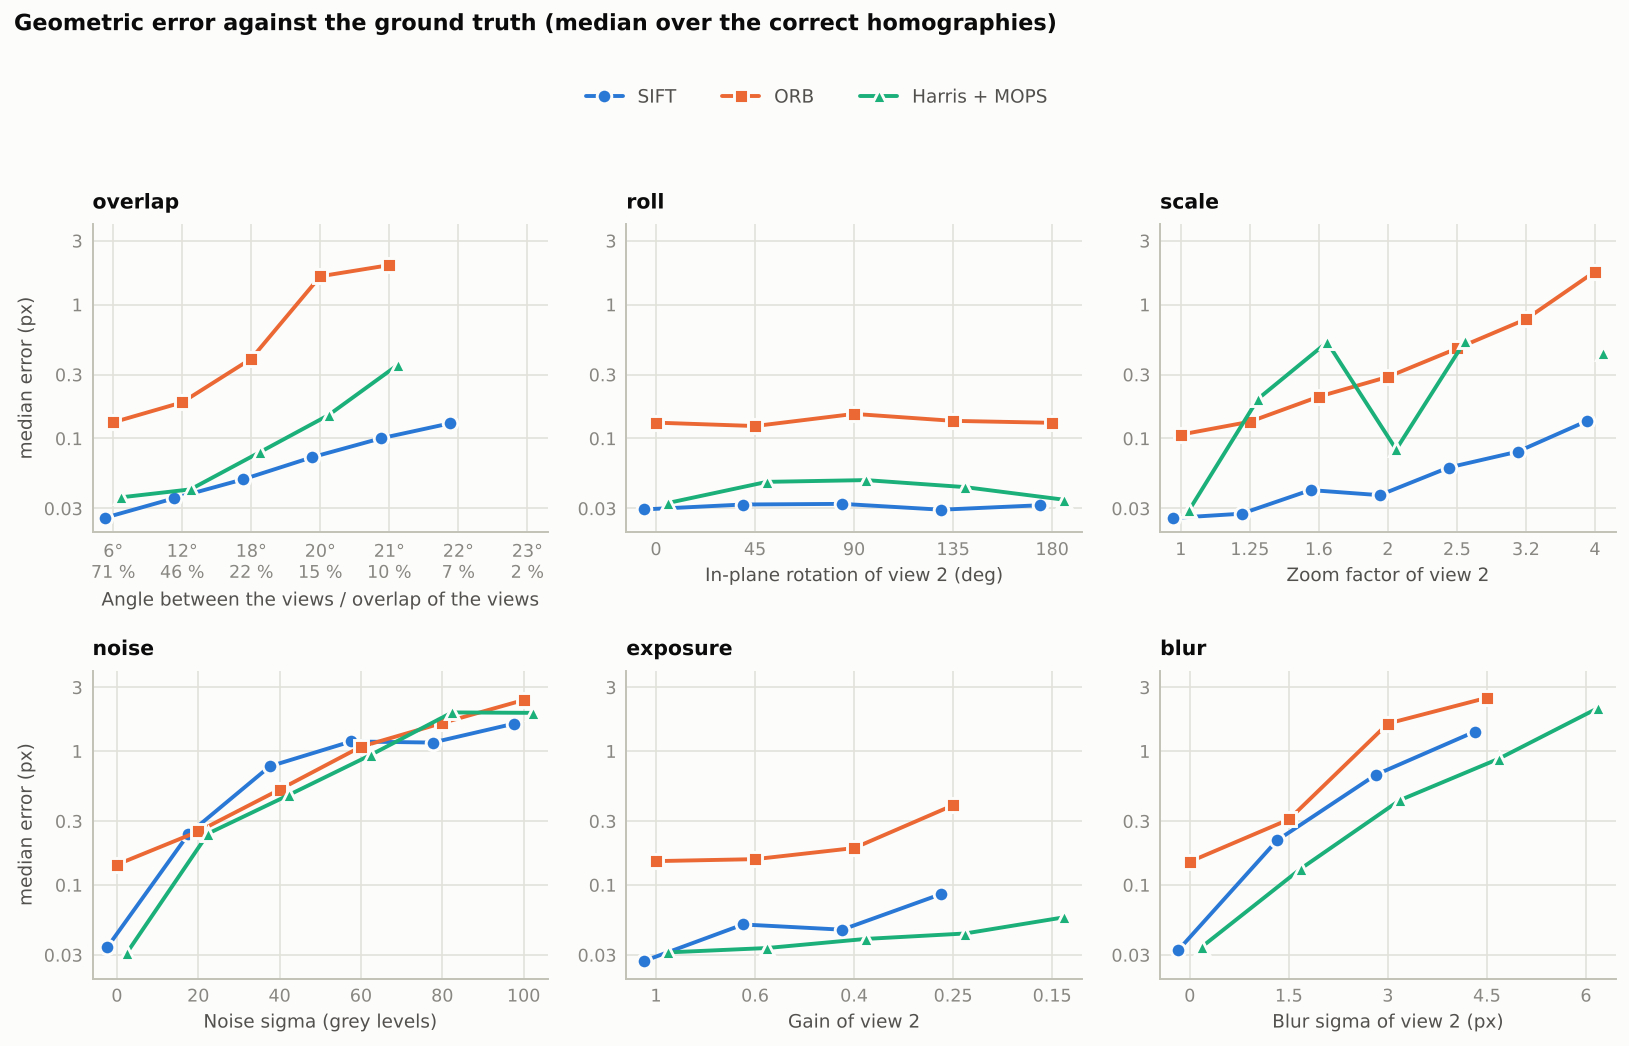

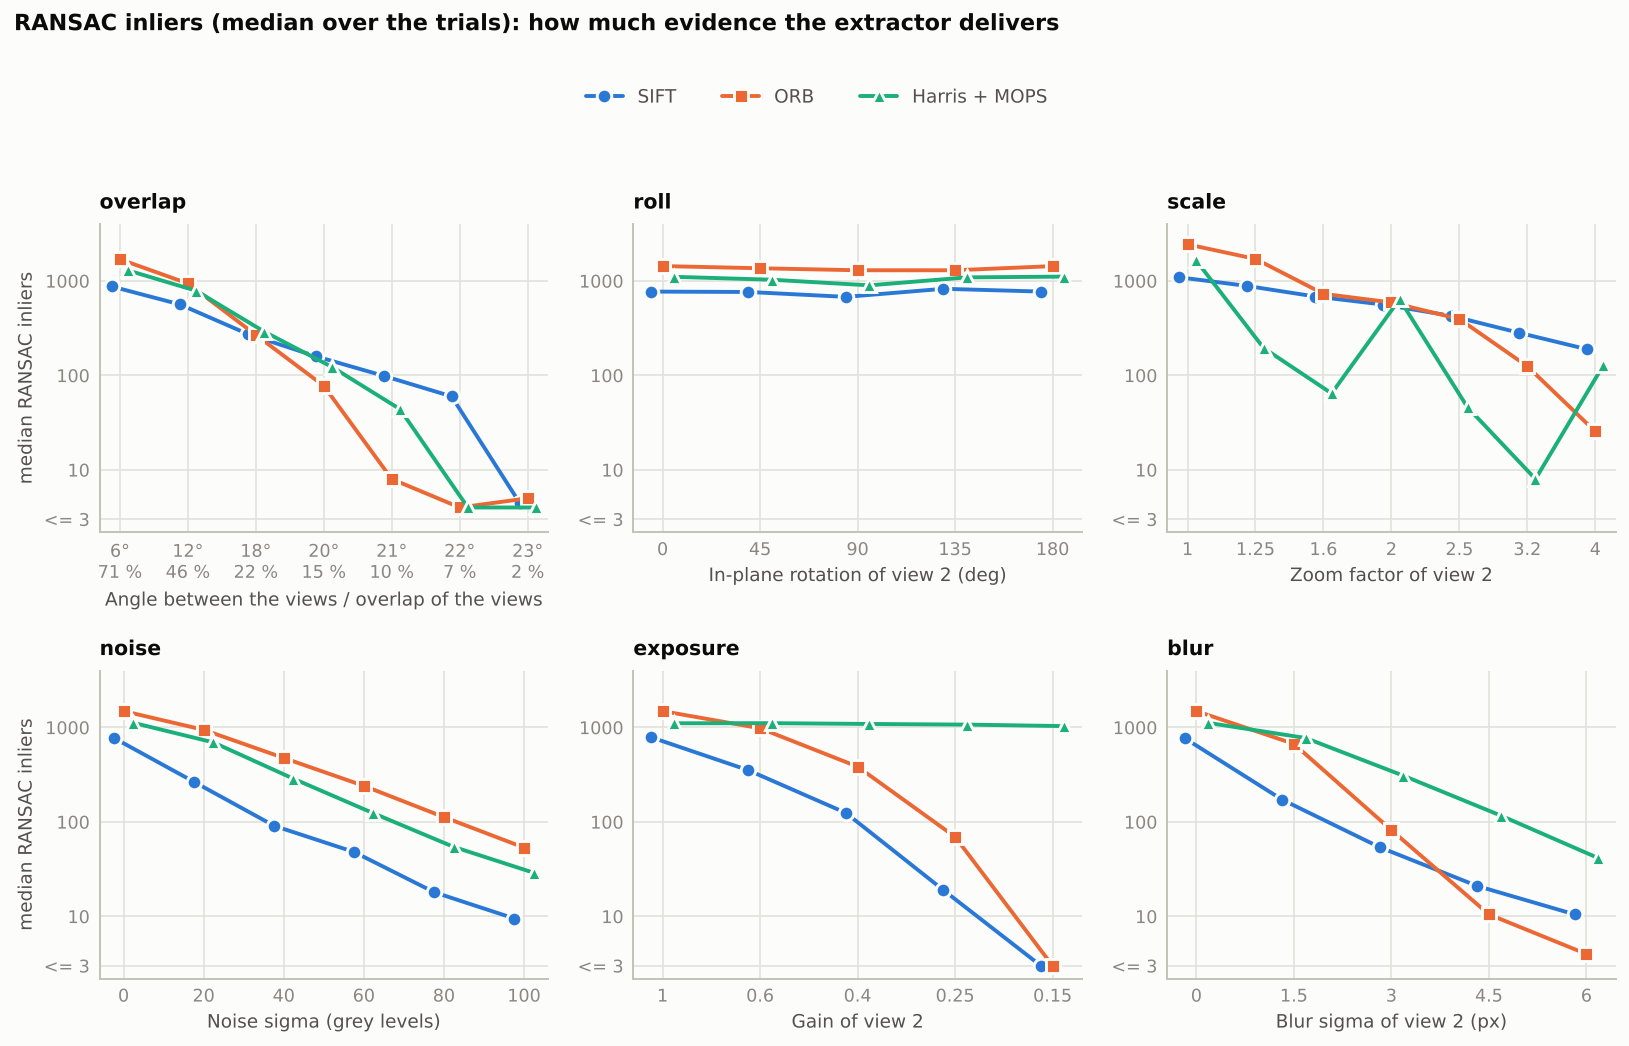

In [27]:
for name in ("sweep_success", "sweep_error", "sweep_inliers"):
    display(Image(filename=str(res_dir / "figures" / f"{name}.png")))

In [28]:
summary = (res_dir / "synthetic" / "summary.md").read_text()
display(Markdown("**Limit of every extractor" + summary.split("**Limit of every extractor")[1]))

rows_csv = viz.read_csv(res_dir / "synthetic" / "summary.csv")
rows = []
for m in METHODS:
    sel = [r for r in rows_csv if r["method"] == m]
    n, acc, ok = (int(sum(r[k] for r in sel)) for k in ("n", "accepted", "correct"))
    rows.append([DESCRIPTIONS[m], n, acc, ok, acc - ok, int(sum(r["wrong_accept"] for r in sel if r["sweep"] == "noise"))])
table(["extractor", "trials", "pairs accepted", "correct (< 3 px)", "silent failures (accepted, >= 3 px)", "of which in the noise sweep"], rows, "lrrrrr")

**Limit of every extractor** - hardest level (levels are ordered easy to hard) up to which at least 90 % of the trials are solved:

| factor | SIFT | ORB | Harris + MOPS |
| :--- | :---: | :---: | :---: |
| overlap | 22° / 7 % | 18° / 22 % | 21° / 10 % |
| roll | 180 (all levels) | 180 (all levels) | 180 (all levels) |
| scale | 4 (all levels) | 2.5 | 2.5 |
| noise | 40 | 60 | 60 |
| exposure | 0.4 | 0.25 | 0.15 (all levels) |
| blur | 3 | 1.5 | 4.5 |


| extractor | trials | pairs accepted | correct (< 3 px) | silent failures (accepted, >= 3 px) | of which in the noise sweep |
| :--- | ---: | ---: | ---: | ---: | ---: |
| SIFT (OpenCV) | 1050 | 887 | 862 | 25 | 16 |
| ORB (OpenCV) | 1050 | 874 | 797 | 77 | 39 |
| Harris + MOPS (from scratch) | 1050 | 955 | 909 | 46 | 30 |

### ***Why do SIFT and ORB fail in dark views while Harris + MOPS does not?***

In the exposure sweep the second view is multiplied by a gain. SIFT and ORB lose every correspondence at gain 0.15; Harris + MOPS does not notice. Two explanations are possible: the *descriptors* might be sensitive to the gain, or the *detectors* do not fire. SIFT's `contrastThreshold` (0.04) and ORB's `fastThreshold` (20 grey levels) are **absolute** limits on contrast, whereas the corner threshold of Harris is relative to the strongest response (1 %). If the detector is to blame, lowering the thresholds in proportion to the gain should fix the problem. Test: count the keypoints, then match a normal view with a view of gain 0.15 and check the homography against the ground truth.

In [29]:
gains = [1.0, 0.6, 0.4, 0.25, 0.15]
dark = [cv2.cvtColor(render_views(world, [ViewSpec(yaw=0, gain=k)], size=(800, 600))[0][0], cv2.COLOR_BGR2GRAY) for k in gains]

variants = {                                             # name: how the view of gain k is processed
    "SIFT, default threshold":  lambda g, k: detect_and_describe(g, "sift"),
    "SIFT, threshold x gain":   lambda g, k: detect_and_describe(g, "sift", sift_contrast=0.04 * k),
    "ORB, default threshold":   lambda g, k: detect_and_describe(g, "orb"),
    "ORB, threshold x gain":    lambda g, k: detect_and_describe(g, "orb", fast_threshold=max(1, round(20 * k))),
    "Harris + MOPS":            lambda g, k: detect_and_describe(g, "harris"),
}
rows = [["grey-level std of the view"] + [f"{g.std():.1f}" for g in dark]]
for name, fn in variants.items():
    rows.append([name] + [len(fn(g, k)) for g, k in zip(dark, gains)])
print("number of keypoints in a view whose gain is ...")
table(["gain"] + [str(k) for k in gains], rows, "l" + "r" * len(gains))

GAIN, TRIALS = 0.15, 4
rng_d = np.random.default_rng(1)
stat = {name: [] for name in variants}
for t in range(TRIALS):
    jit, pit = rng_d.uniform(-3, 3), rng_d.uniform(-2, 2)
    vs, Hg, _ = render_views(world, [ViewSpec(yaw=-4 + jit, pitch=pit), ViewSpec(yaw=4 + jit, pitch=pit, gain=GAIN)], size=(800, 600), seed=t)
    ga, gb = (cv2.cvtColor(v, cv2.COLOR_BGR2GRAY) for v in vs)
    for name, fn in variants.items():
        method = name.split(",")[0].split(" ")[0].lower()
        fa_ = detect_and_describe(ga, method)                       # the normal view always uses the defaults
        fb_ = fn(gb, GAIN)
        if len(fa_) < 4 or len(fb_) < 4:
            stat[name].append((len(fb_), 0, np.inf)); continue
        mt_ = match_features(fa_, fb_)
        H_, inl_, _ = ransac_homography(fa_.kpts[mt_.idx1], fb_.kpts[mt_.idx2], seed=0)
        err = homography_rms_error(H_, Hg[(0, 1)], ga.shape, dst_shape=gb.shape) if H_ is not None else np.inf
        stat[name].append((len(fb_), int(inl_.sum()), err))

rows = [[name, int(np.median([s[0] for s in v])), int(np.median([s[1] for s in v])), f"{sum(s[2] < 3 for s in v)}/{TRIALS}",
         f"{np.median([s[2] for s in v if s[2] < 3]):.2f}" if any(s[2] < 3 for s in v) else "-"] for name, v in stat.items()]
print(f"a view of gain 1 matched with a view of gain {GAIN} ({TRIALS} trials)")
table(["processing of the dark view", "keypoints (median)", "RANSAC inliers (median)", "correct homographies", "median error (px)"], rows, "lrrrr")

number of keypoints in a view whose gain is ...


| gain | 1.0 | 0.6 | 0.4 | 0.25 | 0.15 |
| :--- | ---: | ---: | ---: | ---: | ---: |
| grey-level std of the view | 28.4 | 17.0 | 11.4 | 7.1 | 4.2 |
| SIFT, default threshold | 1453 | 724 | 282 | 60 | 0 |
| SIFT, threshold x gain | 1453 | 1437 | 1468 | 1454 | 1451 |
| ORB, default threshold | 3874 | 2568 | 1012 | 225 | 14 |
| ORB, threshold x gain | 3874 | 3830 | 3763 | 3659 | 3488 |
| Harris + MOPS | 1948 | 1958 | 1959 | 1974 | 1960 |

a view of gain 1 matched with a view of gain 0.15 (4 trials)


| processing of the dark view | keypoints (median) | RANSAC inliers (median) | correct homographies | median error (px) |
| :--- | ---: | ---: | ---: | ---: |
| SIFT, default threshold | 0 | 0 | 0/4 | - |
| SIFT, threshold x gain | 1357 | 658 | 4/4 | 0.10 |
| ORB, default threshold | 6 | 0 | 0/4 | - |
| ORB, threshold x gain | 2860 | 799 | 4/4 | 0.45 |
| Harris + MOPS | 2040 | 1018 | 4/4 | 0.16 |

Scaling the thresholds with the gain restores both detectors completely: at gain 0.15 SIFT has about 1400 keypoints and 660 RANSAC inliers (median error 0.10 px), ORB about 2900 keypoints and 800 inliers (0.45 px), as many as in a normally exposed view. **The failure of SIFT and ORB in dark images is a detector threshold artefact, not a weakness of their descriptors** (SIFT's descriptor is normalised, ORB's comparisons are monotonic). The practical lesson: a fixed absolute threshold needs the images to be exposure-normalised first, or the threshold must adapt to the image contrast; the relative thresholds of Harris + MOPS, together with its normalised patches, give the invariance for free.

### ***Why does Harris + MOPS fail at zoom 3.2 but succeed at 4?***

In the scale sweep Harris + MOPS is perfect up to 2.5×, fails completely at 3.2× and works again at 4×. A pyramid with factor 2 samples the scale only once per octave. A patch of view 1 at pyramid level $l$ can be compared with the patch of view 2 at level $l'$ with $s_2/s_1 \approx 2^{l'-l}$; if the true zoom is $z$, the best level pair is off by $|\log_2 z - \text{round}(\log_2 z)|$ octaves — at most half an octave, a factor $\sqrt2$ in size. The mismatch vanishes at $z = 1, 2, 4, \dots$ and is largest at $z = \sqrt2, 2\sqrt2,\dots$. So the number of RANSAC inliers should be a **sawtooth** in $\log_2 z$ with a period of one octave, with the minima at the half-octave points. A finer sweep (3 trials per zoom factor, median):

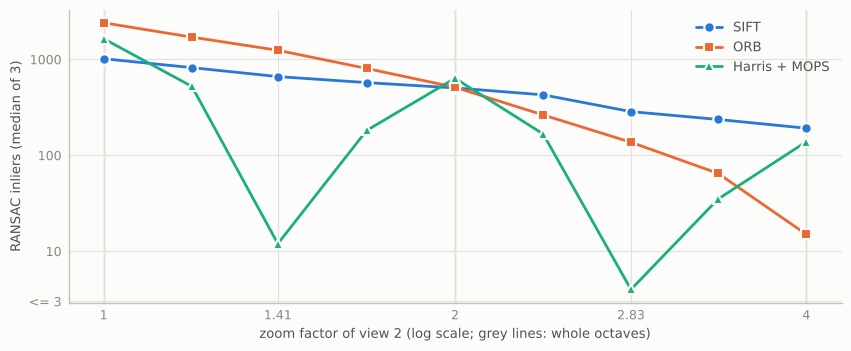

| zoom | 1 | 1.19 | 1.41 | 1.68 | 2 | 2.38 | 2.83 | 3.36 | 4 |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| SIFT (OpenCV) | 1018 | 822 | 663 | 574 | 505 | 428 | 286 | 237 | 192 |
| ORB (OpenCV) | 2410 | 1710 | 1247 | 806 | 513 | 264 | 137 | 65 | 15 |
| Harris + MOPS (from scratch) | 1645 | 524 | 12 | 182 | 636 | 167 | 4 | 35 | 139 |

In [30]:
zooms = [1.0, 1.19, 1.41, 1.68, 2.0, 2.38, 2.83, 3.36, 4.0]
inl_by_zoom = {m: [] for m in METHODS}
for z in zooms:
    pairs_ = []
    for t in range(3):
        a_, b_ = sweep_pair("scale", z, np.random.default_rng(100 * t + 7))
        vs, _, _ = render_views(world, [a_, b_], size=(800, 600), seed=t)
        pairs_.append([cv2.cvtColor(v, cv2.COLOR_BGR2GRAY) for v in vs])
    for m in METHODS:
        counts = []
        for ga, gb in pairs_:
            fa_, fb_ = detect_and_describe(ga, m), detect_and_describe(gb, m)
            mt_ = match_features(fa_, fb_)
            counts.append(int(ransac_homography(fa_.kpts[mt_.idx1], fb_.kpts[mt_.idx2], seed=0)[1].sum()))
        inl_by_zoom[m].append(int(np.median(counts)))

fig, ax = plt.subplots(figsize=(8.6, 3.6))
for m in METHODS:
    s = viz.SERIES[m]
    ax.plot(np.log2(zooms), np.maximum(inl_by_zoom[m], 3), color=s["color"], marker=s["marker"], markeredgecolor=viz.SURFACE, markeredgewidth=1.5)
ax.set_yscale("log")
ax.set_yticks([3, 10, 100, 1000]); ax.set_yticklabels(["<= 3", "10", "100", "1000"]); ax.minorticks_off()
ax.set_xticks(np.log2([1, 1.41, 2, 2.83, 4])); ax.set_xticklabels(["1", "1.41", "2", "2.83", "4"])
for k in (0, 1, 2):
    ax.axvline(k, color=viz.AXIS, linewidth=1.0, zorder=0)
ax.set_xlabel("zoom factor of view 2 (log scale; grey lines: whole octaves)")
ax.set_ylabel("RANSAC inliers (median of 3)")
ax.legend(handles=viz.method_handles(), loc="upper right")
fig.tight_layout()
show_fig(fig)
table(["zoom"] + [f"{z:g}" for z in zooms], [[DESCRIPTIONS[m]] + inl_by_zoom[m] for m in METHODS], "l" + "r" * len(zooms))

**Reading the figure.** The Harris + MOPS curve is the predicted sawtooth: its inliers peak at the whole octaves (1645 at zoom 1, 636 at zoom 2, 139 at zoom 4) and nearly vanish at the half-octave points (12 at 1.41, 4 at 2.83). The peaks fall from octave to octave because view 2, which covers only a fraction $1/z^2$ of view 1, shows detail that view 1 cannot resolve. SIFT shows no sawtooth: its scale space has three intervals per octave (the worst mismatch is a sixth of an octave, a factor 1.12) and its inliers decay smoothly, 1018 → 192. ORB's pyramid has 8 levels with a factor 1.2, so it covers scale changes up to $1.2^7\approx3.6$ and loses the pair beyond that range (15 inliers at zoom 4).

## **Discussion**

### ***What each stage of the pipeline does, and what it costs when it fails***

| stage | role | what goes wrong without it / when it fails | main parameter |
| :--- | :--- | :--- | :--- |
| resize + grey | the descriptors only need the luminance; resizing to at most 1000 px cuts the 10 Mpx of the boat photographs 15-fold, and the cost of every later stage with it | colour adds nothing to the geometry; a larger image costs time, and the RANSAC threshold of 3 px would have to be rescaled | `max_side` |
| detection | finds points that can be found again in another view (corners, blobs) | **everything downstream can only use what was detected**: no keypoints in a region ⇒ no constraint there (the dark-view experiment) | number of keypoints, thresholds |
| description | a signature of the neighbourhood that is *invariant* to the expected change (rotation: orientation; scale: pyramid; exposure: normalisation) and *distinctive* | not invariant ⇒ true pairs look different (the zoom sawtooth); not distinctive ⇒ false pairs look alike (repeated text) | descriptor, orientation, scale sampling |
| matching | for every keypoint the nearest descriptor in the other image; the ratio test discards ambiguous matches, the one-to-one filter discards competing ones | without the ratio test about half of the putative matches are wrong (the figure above at τ = 1), and RANSAC then needs far more iterations (table above) | `ratio = 0.75` |
| homography | normalised DLT inside RANSAC (adaptive number of iterations), refined by Levenberg–Marquardt on the inliers; three acceptance tests (inliers, rank of the DLT matrix, plausible footprint) | outliers ruin a least-squares fit; a degenerate sample (collinear points) gives a family of solutions; a wrong pair must not enter the panorama | `ransac_thresh = 3 px`, `min_inliers = 20` |
| overlap graph | edge weight = number of inliers; the maximum spanning tree connects all images with the most reliable pairs; the reference is the centre of the tree | errors accumulate along a chain of homographies, so the reference minimises the longest chain; images that do not overlap are dropped instead of crashing | – |
| warping | inverse mapping + bilinear interpolation onto a canvas that contains all footprints | forward mapping leaves holes; nearest-neighbour sampling gives jagged edges | `max_canvas_side` |
| blending | hides the transitions: multi-band blending mixes low frequencies over a wide zone and detail over a narrow one; gain compensation equalises the exposure | seams (exposure), ghosts (registration error, parallax, moving objects) | `num_levels`, `gain_compensation` |

### ***Which extractor, and when? The evidence***

Everything in this table is read from the stored results of the experiments above (`scenes.csv`, `synthetic/summary.csv`, `synthetic/summary.md`).

In [31]:
rows_s = viz.read_csv(PANO_RESULT_DIR / "scenes.csv")
rows_y = viz.read_csv(PANO_RESULT_DIR / "synthetic" / "summary.csv")
limit_md = (PANO_RESULT_DIR / "synthetic" / "summary.md").read_text().split("**Limit of every extractor")[1]
limits = {}
for line in limit_md.splitlines():
    cells = [c.strip() for c in line.strip().strip("|").split("|")]
    if len(cells) == 4 and cells[0] in SWEEPS:
        limits[cells[0]] = cells[1:]

mean_ = lambda m, k: float(np.nanmean([r[k] for r in rows_s if r["method"] == m]))
per_ms = lambda m, key, div: 1000.0 * sum(r[key] for r in rows_s if r["method"] == m) / sum(div(r) for r in rows_s if r["method"] == m)
n_images = lambda r: r["n_images"]
n_pairs = lambda r: r["n_images"] * (r["n_images"] - 1) / 2
per_pair_kp = lambda m: 1000.0 * sum(r["t_matching"] for r in rows_s if r["method"] == m) / (
    sum(n_pairs(r) * r["kp_mean"] ** 2 for r in rows_s if r["method"] == m) / 1e6)       # ms per 10^6 keypoint pairs
silent = lambda m: int(sum(r["wrong_accept"] for r in rows_y if r["method"] == m))
n_trials = int(sum(r["n"] for r in rows_y if r["method"] == "sift"))

blank = ["", "", ""]
table(["", *[DESCRIPTIONS[m] for m in METHODS]], [
    ["**Real scenes (5 scenes, 15 stitched panoramas)**", *blank],
    ["RMS reprojection error of the inliers, mean (px)", *[f"{mean_(m, 'rmse_tree'):.2f}" for m in METHODS]],
    ["inlier ratio, mean", *[f"{mean_(m, 'inlier_ratio'):.2f}" for m in METHODS]],
    ["**Controlled study: hardest level still solved in >= 90 % of 30 trials**", *blank],
    ["angle between the views (deg) / overlap area", *limits["overlap"]],
    ["in-plane rotation of view 2 (deg)", *limits["roll"]],
    ["zoom of view 2", *limits["scale"]],
    ["noise sigma (grey levels)", *limits["noise"]],
    ["gain of view 2 (smaller = darker)", *limits["exposure"]],
    ["blur sigma of view 2 (px)", *limits["blur"]],
    [f"pair accepted but homography wrong (of {n_trials} trials)", *[silent(m) for m in METHODS]],
    ["**Run time (this implementation, one run)**", *blank],
    ["feature extraction per image (ms)", *[f"{per_ms(m, 't_features', n_images):.0f}" for m in METHODS]],
    ["matching per pair (ms)", *[f"{per_ms(m, 't_matching', n_pairs):.0f}" for m in METHODS]],
    ["matching per million keypoint pairs (ms)", *[f"{per_pair_kp(m):.1f}" for m in METHODS]],
    ["RANSAC per pair (ms)", *[f"{per_ms(m, 't_ransac', n_pairs):.0f}" for m in METHODS]],
], "lccc")

|  | SIFT (OpenCV) | ORB (OpenCV) | Harris + MOPS (from scratch) |
| :--- | :---: | :---: | :---: |
| **Real scenes (5 scenes, 15 stitched panoramas)** |  |  |  |
| RMS reprojection error of the inliers, mean (px) | 0.65 | 1.08 | 0.83 |
| inlier ratio, mean | 0.89 | 0.92 | 0.94 |
| **Controlled study: hardest level still solved in >= 90 % of 30 trials** |  |  |  |
| angle between the views (deg) / overlap area | 22° / 7 % | 18° / 22 % | 21° / 10 % |
| in-plane rotation of view 2 (deg) | 180 (all levels) | 180 (all levels) | 180 (all levels) |
| zoom of view 2 | 4 (all levels) | 2.5 | 2.5 |
| noise sigma (grey levels) | 40 | 60 | 60 |
| gain of view 2 (smaller = darker) | 0.4 | 0.25 | 0.15 (all levels) |
| blur sigma of view 2 (px) | 3 | 1.5 | 4.5 |
| pair accepted but homography wrong (of 1050 trials) | 25 | 77 | 46 |
| **Run time (this implementation, one run)** |  |  |  |
| feature extraction per image (ms) | 144 | 18 | 297 |
| matching per pair (ms) | 91 | 151 | 70 |
| matching per million keypoint pairs (ms) | 9.1 | 9.9 | 8.3 |
| RANSAC per pair (ms) | 43 | 29 | 30 |

**SIFT (OpenCV).**
*Strengths:* the most accurate geometry in every real scene (0.65 px on average) and in the overlap, roll, zoom and exposure sweeps of the controlled study (median error 0.03–0.13 px), and the widest range: it solves the smallest overlap (7 % of the area) and every zoom up to 4×, with a smooth loss of inliers because its scale space has three intervals per octave.
*Weaknesses:* its `contrastThreshold` is an absolute limit, so it finds nothing in a dark view unless the threshold is scaled with the exposure (the experiment above — the descriptor itself is fine); it is the extractor hurt most by heavy noise (22 of 30 pairs solved at σ = 60 grey levels, against 28 for ORB and 27 for Harris + MOPS); its 128-dimensional float descriptors take the most memory (512 bytes each, against 32 for ORB and 256 for Harris + MOPS).

**ORB (OpenCV).**
*Strengths:* by far the cheapest extraction (about an order of magnitude faster than SIFT) and a compact 256-bit binary descriptor; the best tolerance of noise together with Harris + MOPS.
*Weaknesses:* the least accurate geometry (1.08 px on average: FAST corners sit at integer pixel positions of a pyramid with factor 1.2) and the narrowest range — it loses a pair first when the overlap shrinks (22 % of the area against 7 % for SIFT), at zoom above 2.5× and with a blur above σ = 1.5 px. (Like SIFT it depends on an absolute threshold and fails in dark views; it happens to hold on a little longer, down to a gain of 0.25.) It also has the most *silent* failures (accepted, but wrong). Its matching time per pair is the longest only because it keeps the most keypoints (3900 per image on average): per million keypoint pairs the three descriptors cost the same, 8–10 ms, in this NumPy implementation (a popcount-based Hamming matcher would be much cheaper for ORB). The run-time rows describe this implementation, not the algorithms, and they fluctuate by tens of per cent between runs on a shared machine.

**Harris + MOPS (from scratch).**
*Strengths:* the cleanest matches (highest inlier ratio, 0.94), the best tolerance of exposure (it solves every gain down to 0.15, because its threshold is relative to the strongest response and its patches are normalised) and of blur (σ up to 4.5 px, plausibly because its patches are sampled from an already blurred pyramid level), second-best accuracy (0.83 px).
*Weaknesses:* the slowest extraction (pure NumPy), a pyramid with factor 2 — scale is sampled once per octave, so the inliers form a sawtooth in the zoom factor and the method fails *between* the octaves (zoom 3.2×) while it works at 4× — and a simple descriptor (8 × 8 patch).

**Recommendation.** Use SIFT when the geometry has to be accurate and the conditions are not controlled (small overlap, zoom, blur). Use ORB when speed matters and the photographs are sharp, well exposed and overlap generously. Whichever is used, normalise the exposure before an absolute-threshold detector sees the images, or let the threshold follow the image contrast.

### ***Successes and failures***

**What worked.** All 15 combinations (5 scenes × 3 extractors) were stitched without manual intervention, with reprojection errors around or below one pixel. Every component written from scratch agrees with an independent reference (41 tests: matching against `cv2.BFMatcher`, warping against `cv2.warpPerspective`, DLT and RANSAC against known homographies, Harris + MOPS against a known rotation, the whole pipeline against synthetic views with exact ground truth). The controlled study (≈ 3 × 1050 trials) turned qualitative impressions into measured limits and led to three explanations that were then *tested*, not guessed: dark views (detector threshold), the Harris sawtooth (octave sampling), the false pair (repeated text).

**What failed, and why.**

* **Wrong pairs that are accepted.** The three acceptance tests (inliers, rank, footprint) stopped the repeated-text false pair, but they are safety nets, not guarantees: the controlled study contains 25 (SIFT), 77 (ORB) and 46 (Harris + MOPS) accepted pairs whose homography is off by 3 px or more, mostly at the edge of an extractor's range (heavy noise). A global consistency check over the whole graph — the product of the homographies around a cycle must be the identity — could flag more of them; it is not implemented.
* **Repeated structure.** Lines of text produced 42 "inliers" that were all copies of one point: a homography fitted to them is not determined. The rank test of the DLT matrix detects exactly this.
* **Planar projection.** Every image is mapped onto one plane, which stretches the borders as the field of view grows: the boat panorama is bent and covers a canvas full of black. Wide panoramas need a cylindrical or spherical projection; the images here were stitched on a plane, as the assignment describes.
* **Parallax, moving content and extrapolation.** A homography is exact only for a rotation about the optical centre (or for a plane). The water and the floating ice of the boat set change between the shots: in pairs 0-1 and 1-2 the two lowest bands correlate at 0-0.3 and no shift of up to 12 px improves that. In pair 2-3 the two sky bands are decorrelated and a shift of about (-7, -4) px restores part of the correlation; the inliers of that pair lie in the lower half of the overlap, so the sky is extrapolated (see the two diagnostics above). Multi-band blending hides the seam but cannot remove the ghosts, and no seam optimisation (graph cut) is used.
* **Exposure and colour.** One gain per image is the whole photometric model: no vignetting, no white balance. The greyscale first photographs of the mountain and cathedral sets show that a gain cannot fix a different tonal rendering.
* **Accumulating error.** Pairwise homographies are chained along a spanning tree; there is no bundle adjustment and no loop closure, so a long chain drifts. Measured against pairs that are not tree edges: 0.08-0.26 px on the planar newspaper, 0.6-3.7 px RMS (up to 12 px at the corners) on the boat and cathedral sets when the direct pair has plenty of inliers (`scripts/analyse_chain_drift.py`).
* **Speed.** The matching and the blending are NumPy code written for clarity; the 4-image boat set takes about 13 s with any extractor, 10 s of it in the multi-band blending of a canvas 3300 px wide.

### ***Possible extensions***

* cylindrical / spherical warping and a **bundle adjustment** of the rotations and focal lengths (Brown & Lowe, 2007), which also closes loops;
* seam finding by dynamic programming or graph cut, to route the seam around moving objects;
* exposure normalisation before detection, a vignetting model, and a per-channel gain;
* more extractors (AKAZE and BRISK are absent from the OpenCV 5.0.0 build used here) and a learned detector + matcher as another drop-in first stage;
* the sample photographs of the course, once available: put them in `data/panorama/input/<name>/` and run `python scripts/run_scenes.py`.